# Actividad Evaluativa UA4 — Aprendizaje no supervisado sobre datos transaccionales

**Universidad de La Sabana · Inmersión a la Programación (ADPRO_Python)**

**Estudiantes:** Diego Fernando Sánchez Bayona · Víctor Fabián Novoa Rojas

---

## De qué se trata esta actividad

La guía entrega la base `Online Retail`: todas las transacciones de una tienda minorista en línea
del Reino Unido entre el 1 de diciembre de 2010 y el 9 de diciembre de 2011. La tienda vende
regalos y buena parte de sus clientes son mayoristas. Sobre esa base hay que aplicar aprendizaje
**no supervisado** y responder tres preguntas concretas:

1. ¿Se pueden segmentar los clientes de acuerdo con la cantidad de transacciones y el valor que
   gastan en la tienda?
2. ¿Se pueden identificar transacciones anómalas en este registro?
3. ¿Se pueden identificar clientes atípicos?

La rúbrica califica cuatro criterios de 1,25 puntos cada uno, y este notebook está organizado para
responderlos en orden:

| Criterio de la rúbrica | Puntos | Dónde se responde |
|---|---|---|
| Preparación y exploración de datos transaccionales | 1,25 | Partes 1, 2 y 3 |
| Selección y aplicación de técnicas no supervisadas | 1,25 | Partes 4, 5 y 6 |
| Interpretación y evaluación de resultados | 1,25 | Partes 4 y 7 |
| Análisis de negocio, conclusiones y respuestas | 1,25 | Parte 8 |

## De dónde sale cada técnica

Todo lo que se usa acá viene de los dos casos de la Unidad 4, salvo el RFM, que lo pide la propia
rúbrica de la actividad.

| Técnica | Viene de |
|---|---|
| `StandardScaler` antes de agrupar | **Caso 9**, *Creando el primer modelo de Clusterización* |
| K-means y método del codo con la inercia | **Caso 9**, *El método del codo* |
| Índice de Calinski-Harabasz | **Caso 9** y **Caso 10** |
| Coeficiente de silueta | **Caso 10**, *Clustering con K-means* |
| Clústering jerárquico, dendrograma y enlace de Ward | **Caso 10**, *Clústering Jerárquico* |
| Isolation Forest para detección de anomalías | **Caso 10**, *Detección de anomalías* |
| PCA para reducir y visualizar | **Caso 9** y **Caso 10** |
| t-SNE para validar la agrupación | **Caso 10**, *Validación de los resultados con t-SNE* |
| `crosstab`, `pivot_table` y mapas de calor | **Caso 9** |
| RFM (recencia, frecuencia, valor monetario) | Lo pide la rúbrica de esta actividad |

> **Cómo correr el notebook:** hay variables que se crean arriba y se usan más abajo, así que hay
> que darle **Restart Kernel + Run All**. Si se corre a pedazos salen `NameError`. La base
> `Online Retail.xlsx` debe quedar en la carpeta `data` al lado del notebook.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import json, os
from matplotlib.lines import Line2D

from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.metrics import silhouette_score, calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram, linkage

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

os.makedirs('fig', exist_ok=True)
RES = {}                      # acá se guardan todos los números que después van al informe

print('Librerías cargadas')

Librerías cargadas


---
# PARTE 1 — Cargar la base y ver qué trae

Antes de limpiar cualquier cosa hay que saber qué hay. Este es el mismo primer paso de los casos:
abrir el archivo, mirar la forma de la tabla, los tipos de dato y los nulos.

In [2]:
retail = pd.read_excel('data/Online Retail.xlsx')

print('Filas:', f'{len(retail):,}', '| Columnas:', retail.shape[1])
print('Rango de fechas:', retail['InvoiceDate'].min(), '->', retail['InvoiceDate'].max())
retail.head()

Filas: 541,909 | Columnas: 8
Rango de fechas: 2010-12-01 08:26:00 -> 2011-12-09 12:50:00


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
retail.dtypes

InvoiceNo              object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[us]
UnitPrice             float64
CustomerID            float64
Country                   str
dtype: object

In [4]:
retail.describe()

,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.000000,541909,541909.000000,406829.000000
mean,9.552250,2011-07-04 13:34:57.156386,4.611114,15287.690570
min,-80995.000000,2010-12-01 08:26:00,-11062.060000,12346.000000
25%,1.000000,2011-03-28 11:34:00,1.250000,13953.000000
50%,3.000000,2011-07-19 17:17:00,2.080000,15152.000000
75%,10.000000,2011-10-19 11:27:00,4.130000,16791.000000
max,80995.000000,2011-12-09 12:50:00,38970.000000,18287.000000
std,218.081158,NaN,96.759853,1713.600303


In [5]:
# Nulos por columna: el primer diagnóstico de calidad
nulos = pd.DataFrame({
    'nulos': retail.isna().sum(),
    '% del total': (retail.isna().sum() / len(retail) * 100).round(2)
})
nulos

,nulos,% del total
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Aparece de entrada el problema más serio de esta base: **una cuarta parte de las líneas no tiene
`CustomerID`**. Son ventas reales, con producto, cantidad y precio, pero sin cliente asociado. Eso
tiene una consecuencia directa sobre el diseño del trabajo: cualquier análisis *por cliente* —que
es lo que piden las preguntas 1 y 3 de la guía— solo puede hacerse sobre las líneas que sí lo
tienen. Las demás no se botan: se usan más adelante, en la Parte 6, para buscar **transacciones**
anómalas, donde el cliente no hace falta.

In [6]:
print('Clientes únicos  :', f"{retail['CustomerID'].nunique():,}")
print('Facturas únicas  :', f"{retail['InvoiceNo'].nunique():,}")
print('Productos únicos :', f"{retail['StockCode'].nunique():,}")
print('Países           :', retail['Country'].nunique())

RES['filas_original'] = int(len(retail))
RES['clientes_original'] = int(retail['CustomerID'].nunique())
RES['facturas_original'] = int(retail['InvoiceNo'].nunique())
RES['productos_original'] = int(retail['StockCode'].nunique())
RES['paises'] = int(retail['Country'].nunique())
RES['fecha_min'] = str(retail['InvoiceDate'].min())
RES['fecha_max'] = str(retail['InvoiceDate'].max())

Clientes únicos  : 4,372
Facturas únicas  : 25,900
Productos únicos : 4,070
Países           : 38


In [7]:
# ¿Qué tan concentrada está la base geográficamente?
top_paises = retail['Country'].value_counts()
pct_uk = top_paises.iloc[0] / len(retail) * 100

print(f"El país más grande es {top_paises.index[0]} con el {pct_uk:.1f}% de las líneas.\n")
print(top_paises.head(10).to_string())

RES['pct_uk'] = round(float(pct_uk), 1)
RES['top_paises'] = {k: int(v) for k, v in top_paises.head(6).items()}

El país más grande es United Kingdom con el 91.4% de las líneas.

Country
United Kingdom    495478
Germany             9495
France              8557
EIRE                8196
Spain               2533
Netherlands         2371
Belgium             2069
Switzerland         2002
Portugal            1519
Australia           1259


**El 91 % de las líneas son del Reino Unido.** Esto no es un defecto de la base, es la naturaleza
del negocio, pero hay que decirlo desde el principio: cualquier conclusión de este trabajo describe
sobre todo el mercado británico, y los 37 países restantes aportan tan poco volumen que no
soportarían un análisis propio.

---
# PARTE 2 — Limpieza y preparación de los datos

La rúbrica pide explícitamente *"una limpieza y preprocesamiento exhaustivo y adecuado de los datos
transaccionales, incluyendo el manejo de cancelaciones y datos faltantes"*. Son cuatro problemas
distintos y cada uno se trata distinto, así que primero hay que medir cuánto pesa cada uno antes de
decidir qué hacer con él.

In [8]:
# Problema 1: filas exactamente repetidas
duplicados = retail.duplicated(keep='first')
n_dup = int(duplicados.sum())

print(f'Filas exactamente duplicadas: {n_dup:,} ({n_dup/len(retail)*100:.2f}% de la base)')
print()
print('Ejemplo: la misma línea aparece dos veces en la misma factura y el mismo minuto')
ejemplo = retail[retail.duplicated(subset=None, keep=False)].sort_values(['InvoiceNo', 'StockCode'])
print(ejemplo.head(4).to_string())

RES['n_duplicados'] = n_dup
RES['pct_duplicados'] = round(n_dup / len(retail) * 100, 2)

Filas exactamente duplicadas: 5,268 (0.97% de la base)

Ejemplo: la misma línea aparece dos veces en la misma factura y el mismo minuto
    InvoiceNo StockCode                   Description  Quantity         InvoiceDate  UnitPrice  CustomerID         Country
494    536409     21866   UNION JACK FLAG LUGGAGE TAG         1 2010-12-01 11:45:00       1.25     17908.0  United Kingdom
517    536409     21866   UNION JACK FLAG LUGGAGE TAG         1 2010-12-01 11:45:00       1.25     17908.0  United Kingdom
485    536409     22111  SCOTTIE DOG HOT WATER BOTTLE         1 2010-12-01 11:45:00       4.95     17908.0  United Kingdom
539    536409     22111  SCOTTIE DOG HOT WATER BOTTLE         1 2010-12-01 11:45:00       4.95     17908.0  United Kingdom


Un duplicado exacto repite **todas** las columnas: la misma factura, el mismo producto, la misma
cantidad, el mismo precio y el mismo minuto. No puede tratarse de dos compras distintas del mismo
artículo —eso se registraría como una sola línea con cantidad 2— sino de un registro insertado dos
veces por el sistema. Si se dejan, inflan artificialmente la frecuencia y el gasto de los clientes
afectados.

In [9]:
# Problema 2: cancelaciones. Se marcan con una C al inicio del número de factura
retail['es_cancelacion'] = retail['InvoiceNo'].astype(str).str.startswith('C')
retail['valor'] = retail['Quantity'] * retail['UnitPrice']

n_canc = int(retail['es_cancelacion'].sum())
valor_canc = retail.loc[retail['es_cancelacion'], 'valor'].sum()
valor_bruto = retail.loc[~retail['es_cancelacion'], 'valor'].sum()

print(f"Líneas de cancelación : {n_canc:,}  ({n_canc/len(retail)*100:.1f}% de la base)")
print(f"Facturas canceladas   : {retail.loc[retail['es_cancelacion'], 'InvoiceNo'].nunique():,}")
print(f"Valor devuelto        : GBP {valor_canc:,.0f}")
print(f"Valor vendido (bruto) : GBP {valor_bruto:,.0f}")
print(f"Las devoluciones equivalen al {abs(valor_canc)/valor_bruto*100:.1f}% de la venta bruta")
print()
print(f"De esas cancelaciones, {int((retail['es_cancelacion'] & retail['CustomerID'].notna()).sum()):,} "
      f"tienen cliente identificado y {int((retail['es_cancelacion'] & retail['CustomerID'].isna()).sum()):,} no.")

RES['n_cancelaciones'] = n_canc
RES['valor_cancelado'] = round(float(valor_canc), 0)
RES['valor_bruto'] = round(float(valor_bruto), 0)
RES['pct_devolucion_global'] = round(float(abs(valor_canc) / valor_bruto * 100), 1)
RES['canc_con_cliente'] = int((retail['es_cancelacion'] & retail['CustomerID'].notna()).sum())

Líneas de cancelación : 9,288  (1.7% de la base)
Facturas canceladas   : 3,836
Valor devuelto        : GBP -896,812
Valor vendido (bruto) : GBP 10,644,560
Las devoluciones equivalen al 8.4% de la venta bruta

De esas cancelaciones, 8,905 tienen cliente identificado y 383 no.


Las devoluciones no son un detalle: representan cerca del **9 % de la venta bruta**, y la mayoría
lleva cliente identificado, de modo que no las eliminaría ningún filtro de datos faltantes. La
decisión no es borrarlas y seguir. Se separan del flujo de ventas para no distorsionar los totales,
pero se conservan para construir una variable por cliente —la **tasa de devolución**— que en la
Parte 7 resulta decisiva.

In [10]:
# Problema 3: códigos que no son productos (fletes, ajustes, cargos bancarios)
no_producto = retail.loc[~retail['StockCode'].astype(str).str.match(r'^\d{5}'), 'StockCode']
print('Líneas con código que no es de producto:', f'{len(no_producto):,}')
print()
print(no_producto.value_counts().head(12).to_string())

RES['n_no_producto'] = int(len(no_producto))

Líneas con código que no es de producto: 2,995

StockCode
POST            1256
DOT              710
M                571
C2               144
D                 77
S                 63
BANK CHARGES      37
AMAZONFEE         34
CRUK              16
DCGSSGIRL         13
DCGSSBOY          11
gift_0001_20      10


`POST` es el flete, `DOT` el envío por dotcom, `M` un ajuste manual, `BANK CHARGES` un cargo
bancario, `AMAZONFEE` la comisión de plataforma y `CRUK` una donación. Ninguno es mercancía. Si se
dejan, contaminan el análisis por producto y le suben artificialmente el gasto a los clientes que
más pagan por envío.

In [11]:
# Limpieza paso a paso, dejando registro de cuántas filas se van en cada uno
pasos = [{'Paso': '0. Base original', 'Filas': len(retail), 'Se botaron': 0, '% conservado': 100.00}]

def registrar(nombre, df_actual, df_previo):
    pasos.append({'Paso': nombre, 'Filas': len(df_actual),
                  'Se botaron': len(df_previo) - len(df_actual),
                  '% conservado': round(len(df_actual) / RES['filas_original'] * 100, 2)})

base = retail.copy()

prev = base
base = base[~base.duplicated(keep='first')]
registrar('1. Quitar filas exactamente duplicadas', base, prev)

prev = base
base = base[base['StockCode'].astype(str).str.match(r'^\d{5}')]
registrar('2. Quitar códigos que no son producto', base, prev)

prev = base
ventas = base[~base['es_cancelacion']].copy()
devoluciones = base[base['es_cancelacion']].copy()
registrar('3. Separar las cancelaciones', ventas, prev)

prev = ventas
ventas = ventas[ventas['UnitPrice'] > 0]
registrar('4. Quitar precio menor o igual a cero', ventas, prev)

prev = ventas
ventas = ventas[ventas['Quantity'] > 0]
registrar('5. Quitar cantidad menor o igual a cero', ventas, prev)

prev = ventas
ventas = ventas.dropna(subset=['Description'])
registrar('6. Quitar líneas sin descripción', ventas, prev)

traza = pd.DataFrame(pasos)
print(traza.to_string(index=False))

RES['traza_ventas'] = traza.to_dict('records')
RES['filas_ventas'] = int(len(ventas))
RES['filas_devoluciones'] = int(len(devoluciones))

                                   Paso  Filas  Se botaron  % conservado
                       0. Base original 541909           0        100.00
 1. Quitar filas exactamente duplicadas 536641        5268         99.03
  2. Quitar códigos que no son producto 533652        2989         98.48
           3. Separar las cancelaciones 524984        8668         96.88
  4. Quitar precio menor o igual a cero 522504        2480         96.42
5. Quitar cantidad menor o igual a cero 522504           0         96.42
       6. Quitar líneas sin descripción 522504           0         96.42


In [12]:
# Para el análisis por cliente hace falta el CustomerID
ventas_cli = ventas.dropna(subset=['CustomerID']).copy()
ventas_cli['CustomerID'] = ventas_cli['CustomerID'].astype(int)
sin_cliente = len(ventas) - len(ventas_cli)

print(f"Ventas con cliente identificado : {len(ventas_cli):,} "
      f"({len(ventas_cli)/len(ventas)*100:.1f}% de las ventas limpias)")
print(f"Ventas sin cliente              : {sin_cliente:,}")
print(f"Clientes para el análisis       : {ventas_cli['CustomerID'].nunique():,}")
print(f"Facturas                        : {ventas_cli['InvoiceNo'].nunique():,}")
print(f"Valor de las ventas con cliente : GBP {ventas_cli['valor'].sum():,.0f}")

RES['filas_con_cliente'] = int(len(ventas_cli))
RES['filas_sin_cliente'] = int(sin_cliente)
RES['pct_con_cliente'] = round(len(ventas_cli) / len(ventas) * 100, 1)
RES['clientes_analisis'] = int(ventas_cli['CustomerID'].nunique())
RES['facturas_analisis'] = int(ventas_cli['InvoiceNo'].nunique())
RES['valor_con_cliente'] = round(float(ventas_cli['valor'].sum()), 0)

Ventas con cliente identificado : 391,150 (74.9% de las ventas limpias)
Ventas sin cliente              : 131,354
Clientes para el análisis       : 4,334
Facturas                        : 18,402
Valor de las ventas con cliente : GBP 8,737,228


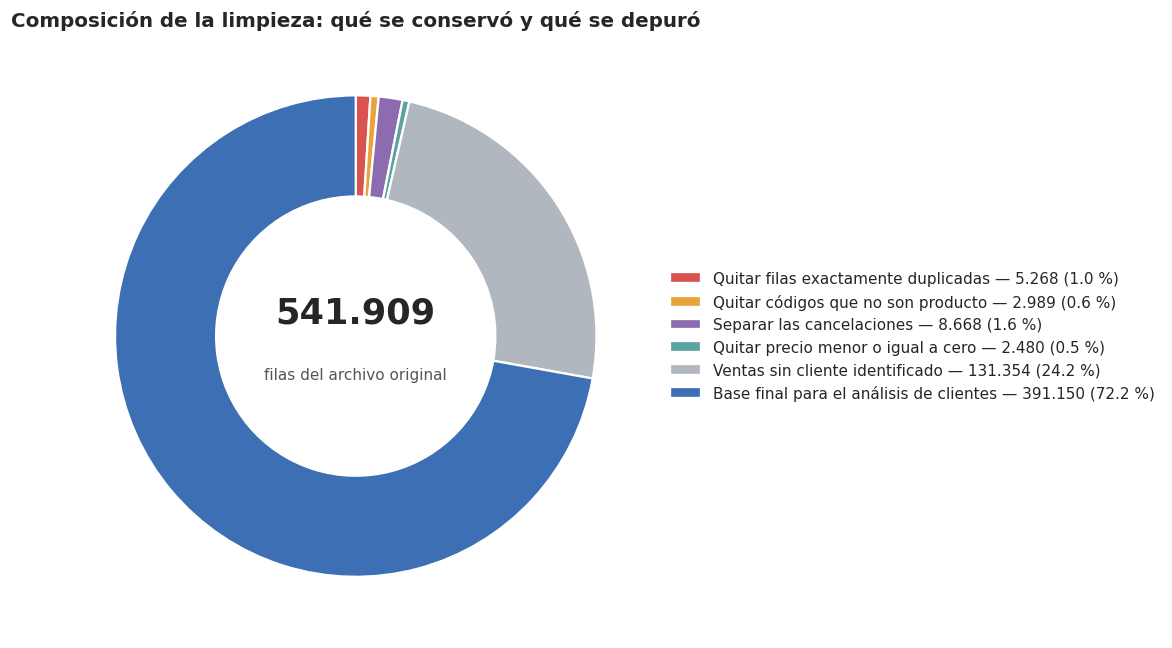

In [13]:
# Composición de la limpieza: en qué se fue cada fila del archivo original
etiquetas, valores = [], []
for p in pasos[1:]:
    if p['Se botaron'] > 0:
        etiquetas.append(p['Paso'][3:])
        valores.append(p['Se botaron'])
etiquetas.append('Ventas sin cliente identificado')
valores.append(sin_cliente)
etiquetas.append('Base final para el análisis de clientes')
valores.append(len(ventas_cli))

colores = ['#D9534F', '#E8A33D', '#8C6BB1', '#5BA3A0', '#B0B7BE', '#3D6FB4']
fig, ax = plt.subplots(figsize=(9.5, 6))
wedges, _ = ax.pie(valores, startangle=90, counterclock=False,
                   colors=colores[:len(valores)],
                   wedgeprops=dict(width=0.42, edgecolor='white', linewidth=1.5))
ax.text(0, 0.1, f'{len(retail):,}'.replace(',', '.'), ha='center', va='center',
        fontsize=23, fontweight='bold')
ax.text(0, -0.16, 'filas del archivo original', ha='center', va='center',
        fontsize=10, color='#555555')

leyenda = [f'{e} — {v:,}'.replace(',', '.') + f' ({v/len(retail)*100:.1f} %)'
           for e, v in zip(etiquetas, valores)]
ax.legend(wedges, leyenda, loc='center left', bbox_to_anchor=(1.0, 0.5), frameon=False, fontsize=10)
ax.set_title('Composición de la limpieza: qué se conservó y qué se depuró',
             fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('fig/f00_composicion.png', bbox_inches='tight')
plt.show()

RES['composicion'] = dict(zip(etiquetas, [int(v) for v in valores]))

---
# PARTE 3 — Exploración de las transacciones

Antes de agrupar clientes conviene entender el pulso del negocio: cuándo compra la gente, qué compra
y qué tan concentrada está la facturación.

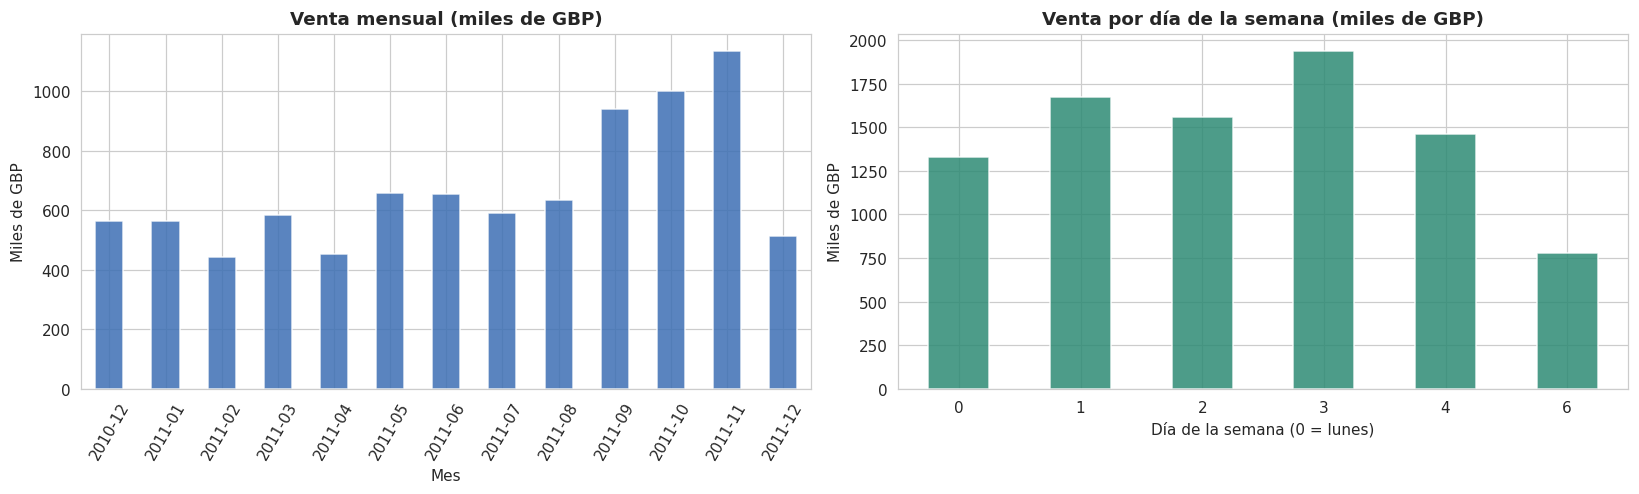

Mes más fuerte: 2011-11 con GBP 1,136,534
Mes más flojo : 2011-02 con GBP 442,294

Venta por día de la semana (miles de GBP):
dia_semana
0    1326.5
1    1672.5
2    1559.5
3    1939.2
4    1459.8
6     779.7


In [14]:
ventas_cli['mes'] = ventas_cli['InvoiceDate'].dt.to_period('M').astype(str)
ventas_cli['dia_semana'] = ventas_cli['InvoiceDate'].dt.dayofweek
ventas_cli['hora'] = ventas_cli['InvoiceDate'].dt.hour

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))

serie_mes = ventas_cli.groupby('mes')['valor'].sum() / 1000
serie_mes.plot(kind='bar', ax=ax[0], color='#3D6FB4', alpha=0.85)
ax[0].set_title('Venta mensual (miles de GBP)', fontweight='bold')
ax[0].set_xlabel('Mes'); ax[0].set_ylabel('Miles de GBP')
ax[0].tick_params(axis='x', rotation=60)

serie_dia = ventas_cli.groupby('dia_semana')['valor'].sum() / 1000
serie_dia.plot(kind='bar', ax=ax[1], color='#2E8B74', alpha=0.85)
ax[1].set_title('Venta por día de la semana (miles de GBP)', fontweight='bold')
ax[1].set_xlabel('Día de la semana (0 = lunes)'); ax[1].set_ylabel('Miles de GBP')
ax[1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.savefig('fig/f01_temporal.png', bbox_inches='tight')
plt.show()

print('Mes más fuerte:', serie_mes.idxmax(), f'con GBP {serie_mes.max()*1000:,.0f}')
print('Mes más flojo :', serie_mes.idxmin(), f'con GBP {serie_mes.min()*1000:,.0f}')
print('\nVenta por día de la semana (miles de GBP):')
print(serie_dia.round(1).to_string())

RES['mes_top'] = str(serie_mes.idxmax())
RES['mes_top_valor'] = round(float(serie_mes.max() * 1000), 0)
RES['mes_min_valor'] = round(float(serie_mes.min() * 1000), 0)
RES['venta_por_dia'] = {int(k): round(float(v * 1000), 0) for k, v in serie_dia.items()}
RES['dias_sin_venta'] = [int(d) for d in range(7) if d not in serie_dia.index]

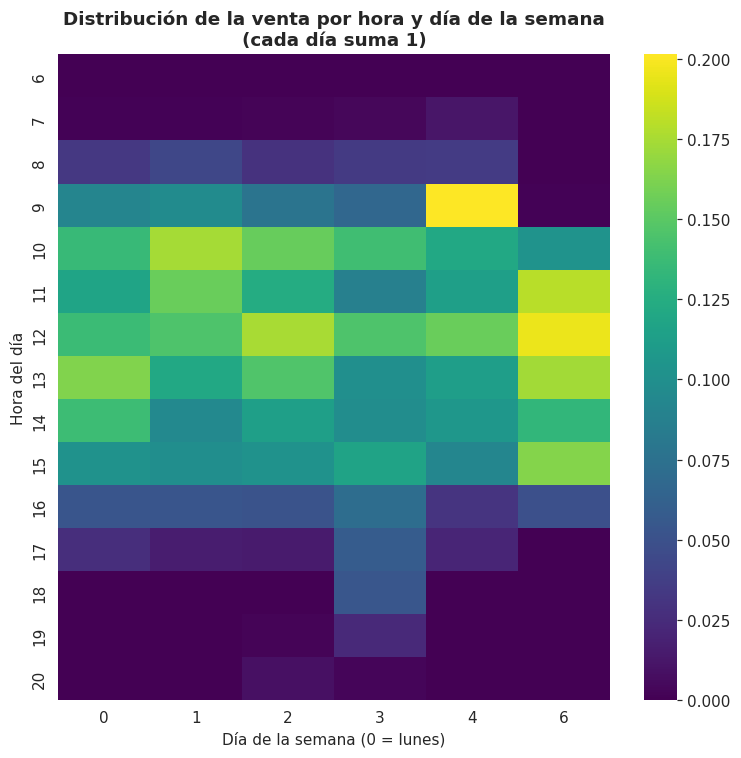

Hora pico de cada día:
dia_semana
0    13
1    10
2    12
3    12
4     9
6    12


In [15]:
# Mapa de calor de la actividad: hora del día contra día de la semana
pivote = ventas_cli.pivot_table(index='hora', columns='dia_semana',
                                values='valor', aggfunc='sum', fill_value=0)
pivote_n = pivote.div(pivote.sum(axis=0), axis=1)

plt.figure(figsize=(7, 7))
sns.heatmap(pivote_n, cmap='viridis')
plt.title('Distribución de la venta por hora y día de la semana\n(cada día suma 1)',
          fontweight='bold')
plt.xlabel('Día de la semana (0 = lunes)'); plt.ylabel('Hora del día')
plt.tight_layout()
plt.savefig('fig/f02_heatmap_hora_dia.png', bbox_inches='tight')
plt.show()

print('Hora pico de cada día:')
print(pivote_n.idxmax(axis=0).to_string())
RES['hora_pico_dia'] = {int(k): int(v) for k, v in pivote_n.idxmax(axis=0).items()}
RES['franja_horaria'] = [int(pivote_n.index.min()), int(pivote_n.index.max())]

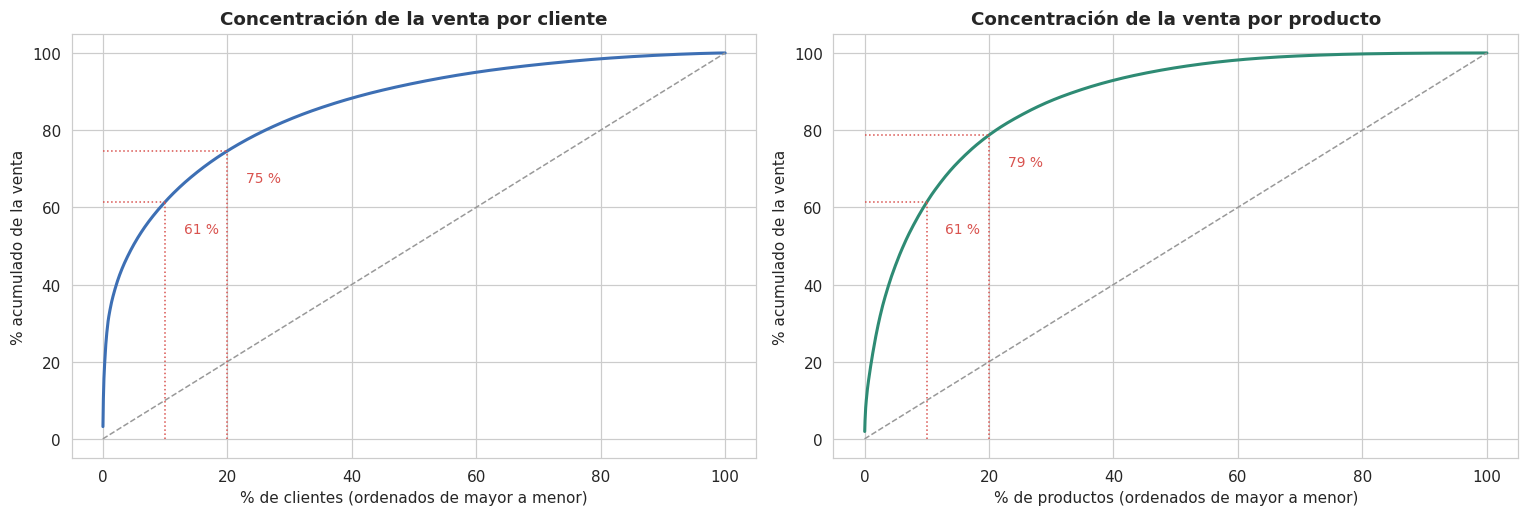

El 1%  de los clientes concentra el 32.0% de la venta
El 10% de los clientes concentra el 61.4% de la venta
El 20% de los clientes concentra el 74.6% de la venta
El 10% de los productos concentra el 61.3% de la venta


In [16]:
# Concentración: ¿el negocio depende de pocos clientes y pocos productos?
por_cliente = ventas_cli.groupby('CustomerID')['valor'].sum().sort_values(ascending=False)
por_producto = ventas_cli.groupby('Description')['valor'].sum().sort_values(ascending=False)

def curva(serie):
    acum = serie.cumsum() / serie.sum() * 100
    eje = np.arange(1, len(serie) + 1) / len(serie) * 100
    return eje, acum.values

ex, ey = curva(por_cliente)
px_, py = curva(por_producto)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.8))
ax[0].plot(ex, ey, color='#3D6FB4', linewidth=2)
ax[0].plot([0, 100], [0, 100], '--', color='#999999', linewidth=1)
ax[0].set_title('Concentración de la venta por cliente', fontweight='bold')
ax[0].set_xlabel('% de clientes (ordenados de mayor a menor)')
ax[0].set_ylabel('% acumulado de la venta')

ax[1].plot(px_, py, color='#2E8B74', linewidth=2)
ax[1].plot([0, 100], [0, 100], '--', color='#999999', linewidth=1)
ax[1].set_title('Concentración de la venta por producto', fontweight='bold')
ax[1].set_xlabel('% de productos (ordenados de mayor a menor)')
ax[1].set_ylabel('% acumulado de la venta')

for a, (e, y) in zip(ax, [(ex, ey), (px_, py)]):
    for marca in (10, 20):
        v = np.interp(marca, e, y)
        a.plot([marca, marca], [0, v], ':', color='#D9534F', linewidth=1)
        a.plot([0, marca], [v, v], ':', color='#D9534F', linewidth=1)
        a.annotate(f'{v:.0f} %', xy=(marca, v), xytext=(marca + 3, v - 8), fontsize=9,
                   color='#D9534F')

plt.tight_layout()
plt.savefig('fig/f12_concentracion.png', bbox_inches='tight')
plt.show()

top1_cli = por_cliente.head(max(1, int(len(por_cliente) * 0.01))).sum() / por_cliente.sum() * 100
top10_cli = por_cliente.head(int(len(por_cliente) * 0.10)).sum() / por_cliente.sum() * 100
top20_cli = por_cliente.head(int(len(por_cliente) * 0.20)).sum() / por_cliente.sum() * 100
top10_prod = por_producto.head(int(len(por_producto) * 0.10)).sum() / por_producto.sum() * 100

print(f'El 1%  de los clientes concentra el {top1_cli:.1f}% de la venta')
print(f'El 10% de los clientes concentra el {top10_cli:.1f}% de la venta')
print(f'El 20% de los clientes concentra el {top20_cli:.1f}% de la venta')
print(f'El 10% de los productos concentra el {top10_prod:.1f}% de la venta')

RES['top1_clientes_pct'] = round(float(top1_cli), 1)
RES['top10_clientes_pct'] = round(float(top10_cli), 1)
RES['top20_clientes_pct'] = round(float(top20_cli), 1)
RES['top10_productos_pct'] = round(float(top10_prod), 1)

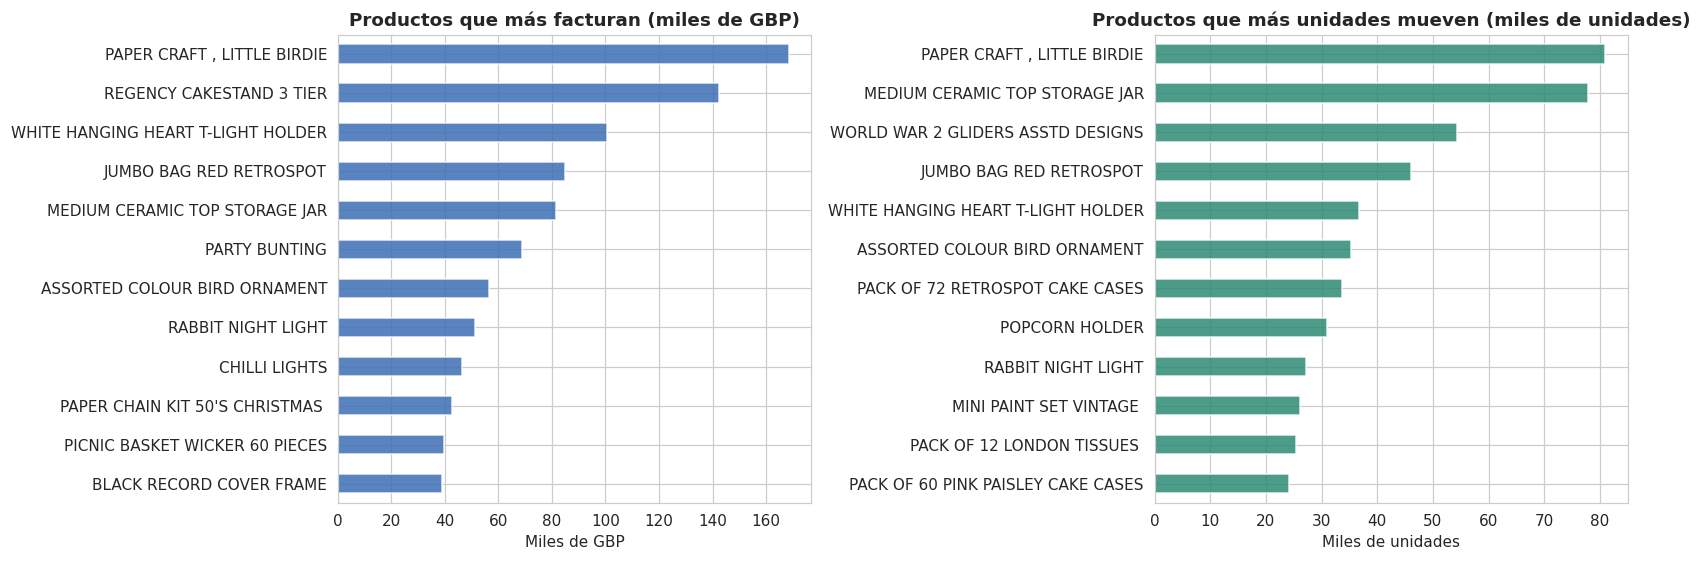

Los 6 productos que más facturan (GBP):
Description
PAPER CRAFT , LITTLE BIRDIE           168470.0
REGENCY CAKESTAND 3 TIER              142265.0
WHITE HANGING HEART T-LIGHT HOLDER    100392.0
JUMBO BAG RED RETROSPOT                85041.0
MEDIUM CERAMIC TOP STORAGE JAR         81417.0
PARTY BUNTING                          68785.0


In [17]:
# Qué se vende: los productos que más facturan y los que más unidades mueven
top_val = por_producto.head(12) / 1000
top_uni = ventas_cli.groupby('Description')['Quantity'].sum().sort_values(ascending=False).head(12) / 1000

fig, ax = plt.subplots(1, 2, figsize=(15, 5.2))
top_val.sort_values().plot(kind='barh', ax=ax[0], color='#3D6FB4', alpha=0.85)
ax[0].set_title('Productos que más facturan (miles de GBP)', fontweight='bold')
ax[0].set_xlabel('Miles de GBP'); ax[0].set_ylabel('')

top_uni.sort_values().plot(kind='barh', ax=ax[1], color='#2E8B74', alpha=0.85)
ax[1].set_title('Productos que más unidades mueven (miles de unidades)', fontweight='bold')
ax[1].set_xlabel('Miles de unidades'); ax[1].set_ylabel('')

plt.tight_layout()
plt.savefig('fig/f13_top_productos.png', bbox_inches='tight')
plt.show()

print('Los 6 productos que más facturan (GBP):')
print(por_producto.head(6).round(0).to_string())

RES['top_productos'] = {str(k): round(float(v), 0) for k, v in por_producto.head(6).items()}
RES['top_producto_1'] = str(por_producto.index[0])
RES['top_producto_1_valor'] = round(float(por_producto.iloc[0]), 0)

---
# PARTE 4 — Construyendo la tabla de clientes (RFM)

Acá se responde el corazón de la primera pregunta de la guía. Para segmentar clientes hay que pasar
de una tabla donde cada fila es una línea de factura a una donde **cada fila es un cliente**. Es el
mismo movimiento que hace el Caso 9 al crear su base de propiedades de clientes.

Las tres variables clásicas para esto son el **RFM**, que la rúbrica nombra explícitamente:

- **Recencia**: cuántos días hace que el cliente compró por última vez. Menos es mejor.
- **Frecuencia**: cuántas facturas distintas hizo en el año.
- **Monetario**: cuánto dinero dejó en total.

A esas tres le agrego otras tres que salen naturales de esta base y aportan información que el RFM
solo no captura: el **ticket promedio**, el **número de productos distintos** que compró y su
**tasa de devolución**, construida con las cancelaciones que separamos en la Parte 2.

In [18]:
# La fecha de referencia es el día siguiente a la última transacción de la base
fecha_ref = ventas_cli['InvoiceDate'].max() + pd.Timedelta(days=1)
print('Fecha de referencia para la recencia:', fecha_ref)

clientes = ventas_cli.groupby('CustomerID').agg(
    recencia=('InvoiceDate', lambda x: (fecha_ref - x.max()).days),
    frecuencia=('InvoiceNo', 'nunique'),
    monetario=('valor', 'sum'),
    productos_distintos=('StockCode', 'nunique'),
    unidades=('Quantity', 'sum'),
)

clientes['ticket_promedio'] = clientes['monetario'] / clientes['frecuencia']

print('Clientes en la tabla:', f'{len(clientes):,}')
clientes.head()

Fecha de referencia para la recencia: 2011-12-10 12:50:00


Clientes en la tabla: 4,334


,recencia,frecuencia,monetario,productos_distintos,unidades,ticket_promedio
CustomerID,,,,,,
12346,326,1,77183.60,1,74215,77183.600000
12347,2,7,4310.00,103,2458,615.714286
12348,75,4,1437.24,21,2332,359.310000
12349,19,1,1457.55,72,630,1457.550000
12350,310,1,294.40,16,196,294.400000


In [19]:
# Tasa de devolución: cuánto devolvió cada cliente respecto a lo que compró
dev = devoluciones.dropna(subset=['CustomerID']).copy()
dev['CustomerID'] = dev['CustomerID'].astype(int)
valor_devuelto = dev.groupby('CustomerID')['valor'].sum().abs()

clientes['valor_devuelto'] = valor_devuelto.reindex(clientes.index).fillna(0)
clientes['tasa_devolucion'] = (clientes['valor_devuelto'] /
                               (clientes['monetario'] + clientes['valor_devuelto']) * 100)

n_con_dev = int((clientes['tasa_devolucion'] > 0).sum())
print(f'Clientes que devolvieron algo: {n_con_dev:,} '
      f'({n_con_dev/len(clientes)*100:.1f}% de los clientes)')
print(f'Tasa de devolución mediana entre los que devuelven: '
      f"{clientes.loc[clientes['tasa_devolucion'] > 0, 'tasa_devolucion'].median():.1f}%")

RES['clientes_con_devolucion'] = n_con_dev
RES['pct_clientes_con_devolucion'] = round(n_con_dev / len(clientes) * 100, 1)

Clientes que devolvieron algo: 1,506 (34.7% de los clientes)
Tasa de devolución mediana entre los que devuelven: 2.0%


In [20]:
# Estadísticas descriptivas de las variables construidas
desc = clientes[['recencia', 'frecuencia', 'monetario', 'ticket_promedio',
                 'productos_distintos', 'tasa_devolucion']].describe().T
desc['CV (%)'] = (desc['std'] / desc['mean'] * 100).round(1)
desc.round(2)

,count,mean,std,min,25%,50%,75%,max,CV (%)
recencia,4334.0,92.70,100.18,1.00,18.00,51.00,143.00,374.00,108.1
frecuencia,4334.0,4.25,7.63,1.00,1.00,2.00,5.00,206.00,179.8
monetario,4334.0,2015.97,8903.67,3.75,304.24,662.56,1631.62,279138.02,441.7
ticket_promedio,4334.0,415.48,1800.90,3.75,177.20,289.56,423.41,84236.25,433.4
productos_distintos,4334.0,61.43,85.31,1.00,16.00,35.00,77.00,1785.00,138.9
tasa_devolucion,4334.0,1.64,5.15,0.00,0.00,0.00,0.97,70.32,313.7


In [21]:
RES['desc_clientes'] = {
    v: {k: round(float(x), 2) for k, x in clientes[v].describe().items()}
    for v in ['recencia', 'frecuencia', 'monetario', 'ticket_promedio',
              'productos_distintos', 'tasa_devolucion']
}
print('Descriptivas guardadas.')
print('\nMediana de gasto por cliente: GBP', round(clientes['monetario'].median(), 0))
print('Promedio de gasto por cliente: GBP', round(clientes['monetario'].mean(), 0))
print('Cliente que más gastó       : GBP', round(clientes['monetario'].max(), 0))

Descriptivas guardadas.

Mediana de gasto por cliente: GBP 663.0
Promedio de gasto por cliente: GBP 2016.0
Cliente que más gastó       : GBP 279138.0


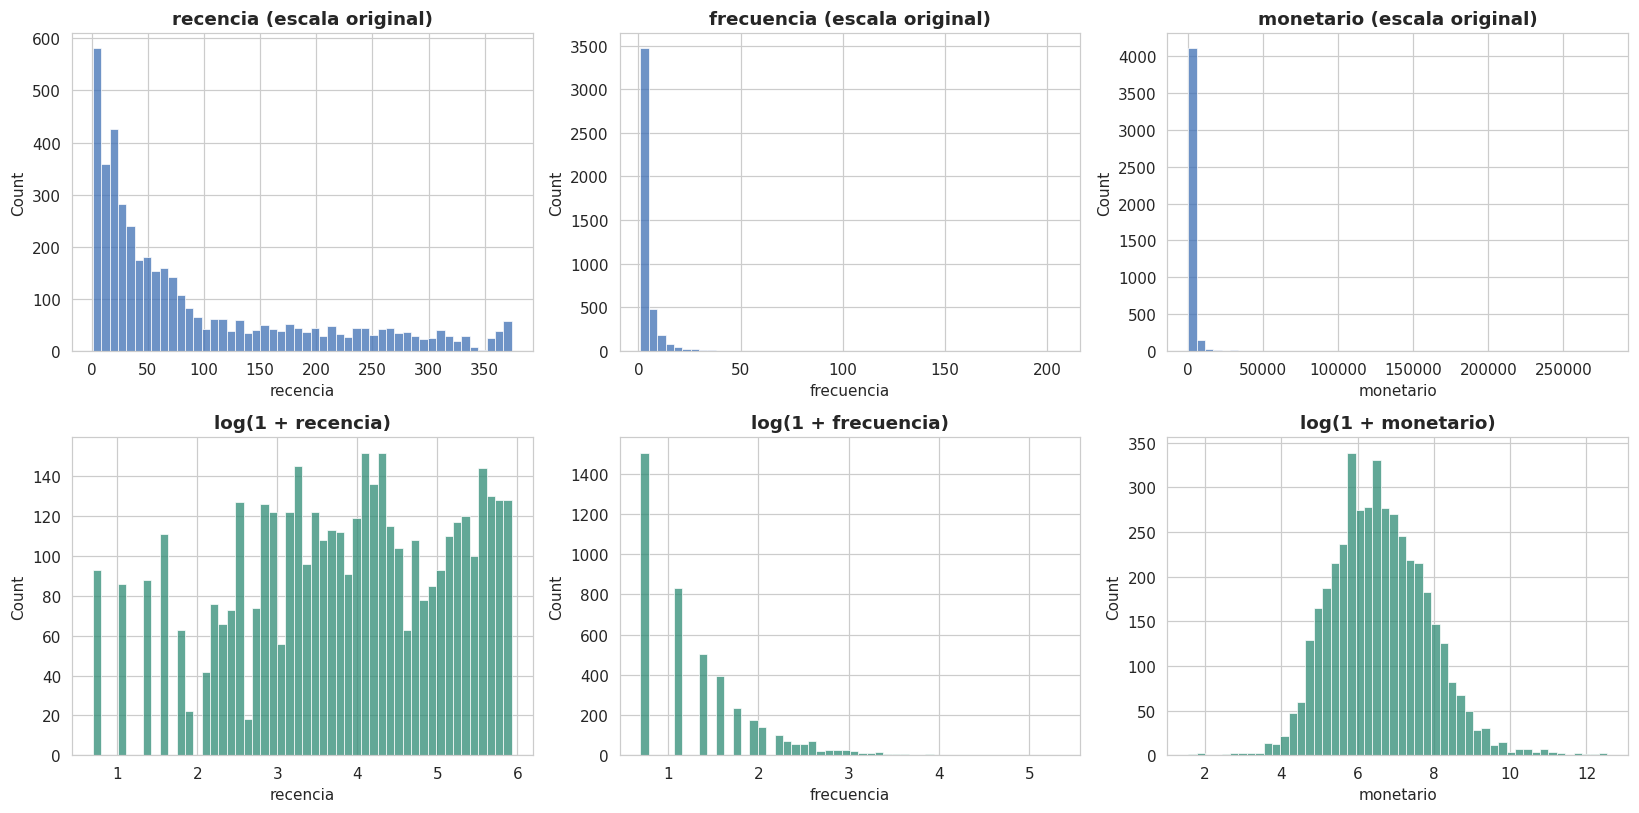

Asimetría en escala original: {'recencia': 1.24, 'frecuencia': 11.95, 'monetario': 19.58}
Asimetría en logaritmo      : {'recencia': -0.38, 'frecuencia': 1.21, 'monetario': 0.4}


In [22]:
# Las tres variables del RFM tienen colas muy largas: se ven mejor en logaritmo
fig, ax = plt.subplots(2, 3, figsize=(15, 7.5))
for j, v in enumerate(['recencia', 'frecuencia', 'monetario']):
    sns.histplot(clientes[v], bins=50, ax=ax[0][j], color='#3D6FB4')
    ax[0][j].set_title(f'{v} (escala original)', fontweight='bold')
    sns.histplot(np.log1p(clientes[v]), bins=50, ax=ax[1][j], color='#2E8B74')
    ax[1][j].set_title(f'log(1 + {v})', fontweight='bold')
plt.tight_layout()
plt.savefig('fig/f03_rfm_distribuciones.png', bbox_inches='tight')
plt.show()

asim = {v: round(float(clientes[v].skew()), 2) for v in ['recencia', 'frecuencia', 'monetario']}
asim_log = {v: round(float(np.log1p(clientes[v]).skew()), 2)
            for v in ['recencia', 'frecuencia', 'monetario']}
print('Asimetría en escala original:', asim)
print('Asimetría en logaritmo      :', asim_log)
RES['asimetria'] = asim
RES['asimetria_log'] = asim_log

La frecuencia y el valor monetario tienen una **asimetría enorme** en su escala original: unos pocos
mayoristas gastan miles de veces más que el cliente típico. Si se agrupa así, K-means solo va a ver
esos extremos y va a meter a todos los demás en un mismo saco. El logaritmo corrige el problema y
deja distribuciones mucho más simétricas, que es exactamente el mismo argumento que usamos en la
UA3 con el precio de los arriendos. Por eso el modelo se construye sobre las variables
logaritmizadas y después estandarizadas, como hace el Caso 9.

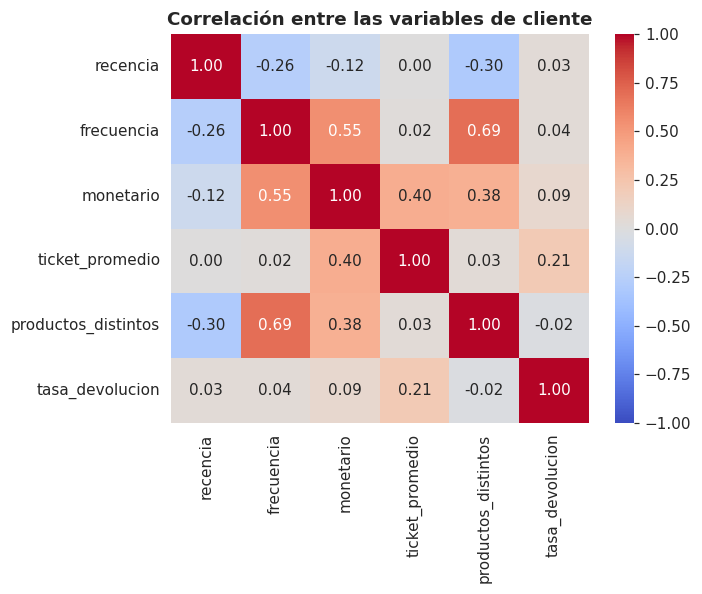

In [23]:
# Matriz de correlación de las variables de cliente
plt.figure(figsize=(6.5, 5.5))
sns.heatmap(clientes[['recencia', 'frecuencia', 'monetario', 'ticket_promedio',
                      'productos_distintos', 'tasa_devolucion']].corr(),
            annot=True, vmin=-1, vmax=1, cmap='coolwarm', fmt='.2f')
plt.title('Correlación entre las variables de cliente', fontweight='bold')
plt.tight_layout()
plt.savefig('fig/f04_correlacion.png', bbox_inches='tight')
plt.show()

---
# PARTE 5 — Segmentación de clientes con K-means

Con la tabla lista se puede responder la primera pregunta de la guía. El procedimiento es el del
Caso 9: transformar, escalar, buscar el número de grupos con tres métricas independientes y recién
ahí correr el modelo.

In [24]:
# Las cuatro variables que entran al modelo, en logaritmo para domar las colas
vars_modelo = ['recencia', 'frecuencia', 'monetario', 'ticket_promedio']
X_log = np.log1p(clientes[vars_modelo])

escalador = StandardScaler()
X = escalador.fit_transform(X_log)

print('Matriz para agrupar:', X.shape)
print('Variables:', vars_modelo)

Matriz para agrupar: (4334, 4)
Variables: ['recencia', 'frecuencia', 'monetario', 'ticket_promedio']


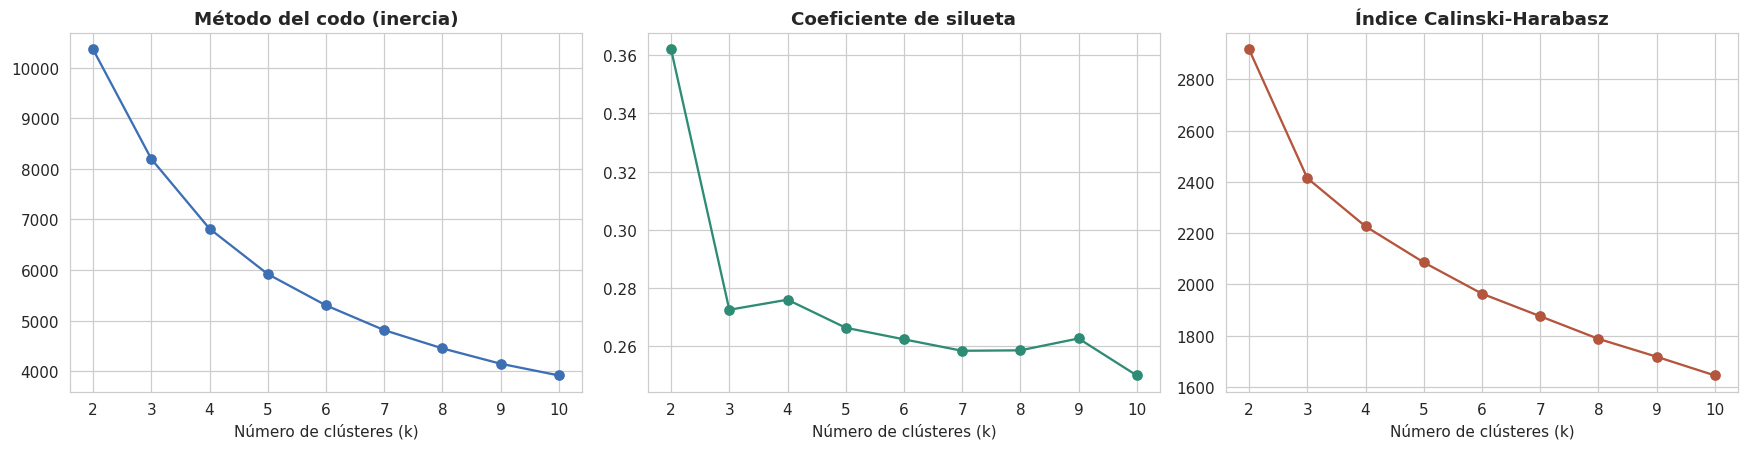

 k  inercia  silueta  calinski_harabasz
 2  10361.5   0.3620             2916.0
 3   8197.1   0.2725             2414.3
 4   6818.5   0.2760             2226.4
 5   5921.6   0.2663             2086.2
 6   5303.1   0.2623             1964.1
 7   4813.3   0.2584             1876.3
 8   4452.6   0.2586             1788.2
 9   4148.8   0.2626             1718.4
10   3917.8   0.2499             1645.5


In [25]:
# Las tres métricas del Caso 9 y el Caso 10, calculadas de una vez
ks = range(2, 11)
inercia, silueta, ch = [], [], []

for k in ks:
    km = KMeans(n_clusters=k, n_init='auto', random_state=42)
    etiquetas = km.fit_predict(X)
    inercia.append(km.inertia_)
    silueta.append(silhouette_score(X, etiquetas))
    ch.append(calinski_harabasz_score(X, etiquetas))

fig, ax = plt.subplots(1, 3, figsize=(16, 4.2))
ax[0].plot(list(ks), inercia, marker='o', color='#3D6FB4')
ax[0].set_title('Método del codo (inercia)', fontweight='bold')
ax[1].plot(list(ks), silueta, marker='o', color='#2E8B74')
ax[1].set_title('Coeficiente de silueta', fontweight='bold')
ax[2].plot(list(ks), ch, marker='o', color='#B4553D')
ax[2].set_title('Índice Calinski-Harabasz', fontweight='bold')
for a in ax:
    a.set_xlabel('Número de clústeres (k)')
plt.tight_layout()
plt.savefig('fig/f05_metricas_k.png', bbox_inches='tight')
plt.show()

tabla_k = pd.DataFrame({'k': list(ks),
                        'inercia': np.round(inercia, 1),
                        'silueta': np.round(silueta, 4),
                        'calinski_harabasz': np.round(ch, 1)})
print(tabla_k.to_string(index=False))

RES['tabla_k'] = tabla_k.to_dict('records')
RES['k_mejor_silueta'] = int(tabla_k.loc[tabla_k['silueta'].idxmax(), 'k'])
RES['k_mejor_ch'] = int(tabla_k.loc[tabla_k['calinski_harabasz'].idxmax(), 'k'])

In [26]:
# Se elige k=4: es el punto donde el codo se dobla y la silueta sigue alta,
# y es el número que permite una lectura de negocio clara.
K = 4
kmeans = KMeans(n_clusters=K, n_init='auto', random_state=42)
clientes['segmento'] = kmeans.fit_predict(X)

sil_final = silhouette_score(X, clientes['segmento'])
ch_final = calinski_harabasz_score(X, clientes['segmento'])

print(f'K-means con k={K}')
print(f'  Coeficiente de silueta   : {sil_final:.4f}')
print(f'  Índice Calinski-Harabasz : {ch_final:.1f}')
print()
print('Clientes por segmento:')
print(clientes['segmento'].value_counts().sort_index().to_string())

RES['K'] = K
RES['silueta_final'] = round(float(sil_final), 4)
RES['ch_final'] = round(float(ch_final), 1)
RES['tam_segmentos'] = {int(k): int(v) for k, v in
                        clientes['segmento'].value_counts().sort_index().items()}

K-means con k=4
  Coeficiente de silueta   : 0.2760
  Índice Calinski-Harabasz : 2226.4

Clientes por segmento:
segmento
0    1082
1    1245
2     830
3    1177


In [27]:
# Perfil de cada segmento: la mediana es más representativa que el promedio con colas largas
perfil = clientes.groupby('segmento').agg(
    clientes=('monetario', 'size'),
    recencia_mediana=('recencia', 'median'),
    frecuencia_mediana=('frecuencia', 'median'),
    gasto_mediano=('monetario', 'median'),
    ticket_mediano=('ticket_promedio', 'median'),
    productos_mediana=('productos_distintos', 'median'),
    devolucion_media=('tasa_devolucion', 'mean'),
    gasto_total=('monetario', 'sum'),
).round(1)
perfil['% de clientes'] = (perfil['clientes'] / perfil['clientes'].sum() * 100).round(1)
perfil['% de la venta'] = (perfil['gasto_total'] / perfil['gasto_total'].sum() * 100).round(1)
perfil

,clientes,recencia_mediana,frecuencia_mediana,gasto_mediano,ticket_mediano,productos_mediana,devolucion_media,gasto_total,% de clientes,% de la venta
segmento,,,,,,,,,,
0,1082,19.0,3.0,698.7,222.5,42.0,1.6,827902.8,25.0,9.5
1,1245,171.0,1.0,200.1,156.3,13.0,1.6,274649.9,28.7,3.1
2,830,11.0,9.0,3439.9,392.7,114.0,2.0,6077182.9,19.2,69.6
3,1177,87.0,2.0,860.1,454.2,37.0,1.6,1557492.1,27.2,17.8


In [28]:
RES['perfil_segmentos'] = {int(i): {k: float(v) for k, v in fila.items()}
                           for i, fila in perfil.iterrows()}
print(perfil.to_string())

          clientes  recencia_mediana  frecuencia_mediana  gasto_mediano  ticket_mediano  productos_mediana  devolucion_media  gasto_total  % de clientes  % de la venta
segmento                                                                                                                                                               
0             1082              19.0                 3.0          698.7           222.5               42.0               1.6     827902.8           25.0            9.5
1             1245             171.0                 1.0          200.1           156.3               13.0               1.6     274649.9           28.7            3.1
2              830              11.0                 9.0         3439.9           392.7              114.0               2.0    6077182.9           19.2           69.6
3             1177              87.0                 2.0          860.1           454.2               37.0               1.6    1557492.1           27.2        

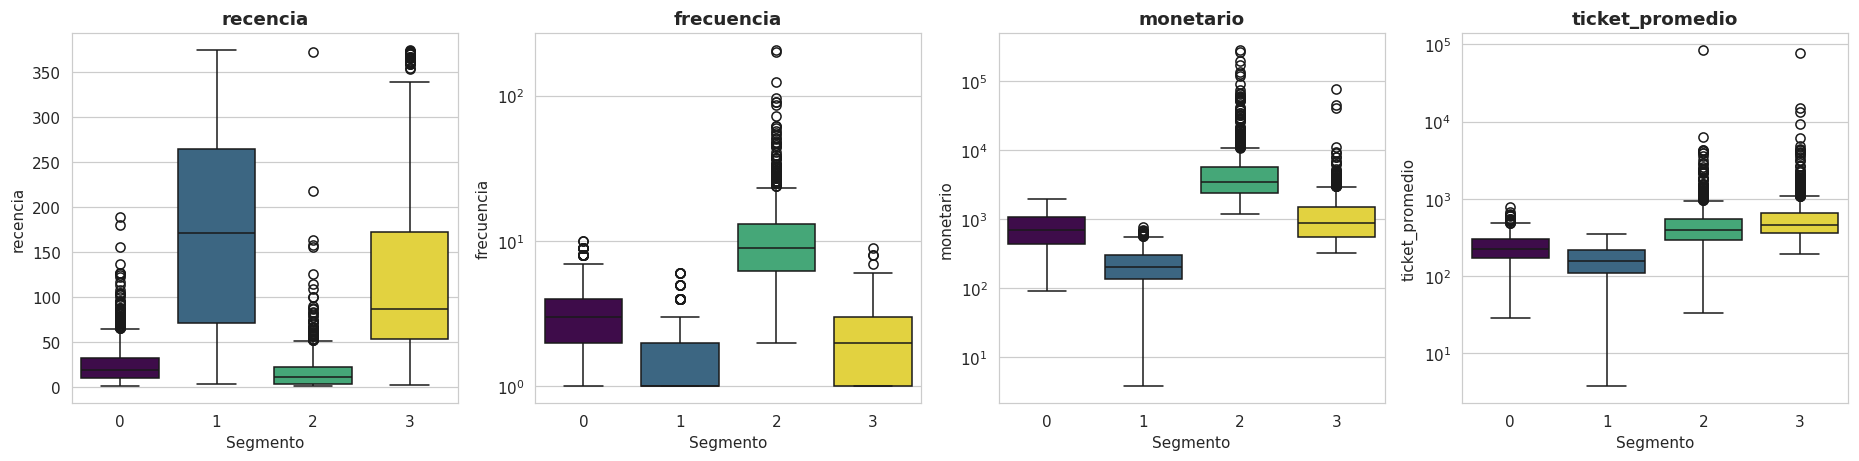

In [29]:
# Cómo se distribuye cada variable dentro de cada segmento
fig, ax = plt.subplots(1, 4, figsize=(17, 4.3))
for j, v in enumerate(vars_modelo):
    sns.boxplot(x=clientes['segmento'], y=clientes[v], hue=clientes['segmento'],
                ax=ax[j], legend=False, palette='viridis')
    ax[j].set_title(v, fontweight='bold')
    ax[j].set_xlabel('Segmento')
    if v != 'recencia':
        ax[j].set_yscale('log')
plt.tight_layout()
plt.savefig('fig/f06_perfiles_segmento.png', bbox_inches='tight')
plt.show()

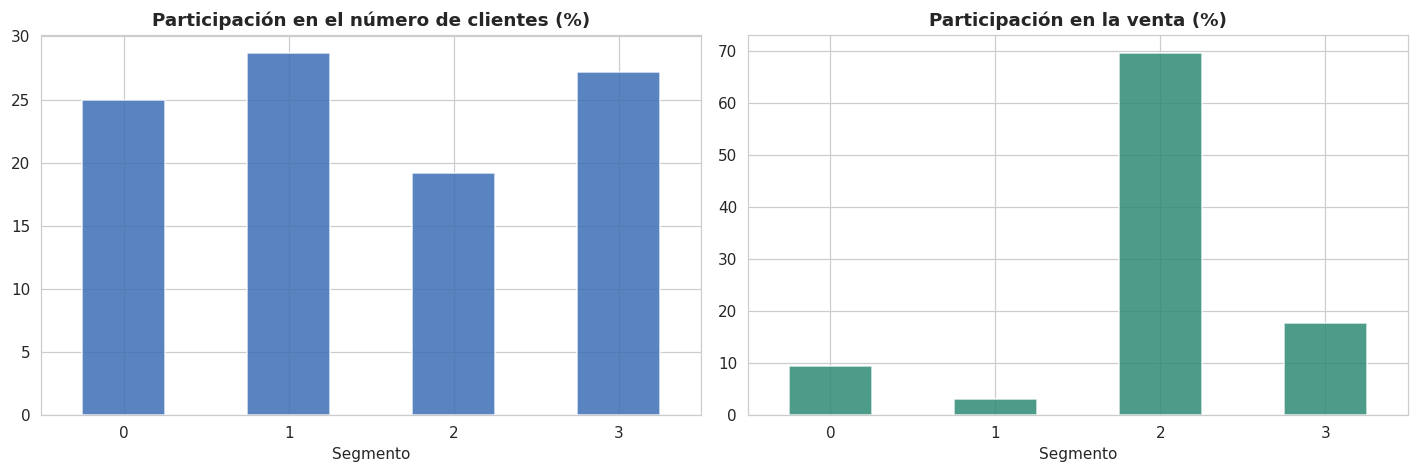

In [30]:
# El aporte de cada segmento al negocio
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4))
perfil['% de clientes'].plot(kind='bar', ax=ax[0], color='#3D6FB4', alpha=0.85)
ax[0].set_title('Participación en el número de clientes (%)', fontweight='bold')
ax[0].set_xlabel('Segmento')
ax[0].tick_params(axis='x', rotation=0)

perfil['% de la venta'].plot(kind='bar', ax=ax[1], color='#2E8B74', alpha=0.85)
ax[1].set_title('Participación en la venta (%)', fontweight='bold')
ax[1].set_xlabel('Segmento')
ax[1].tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.savefig('fig/f07_aporte_segmentos.png', bbox_inches='tight')
plt.show()

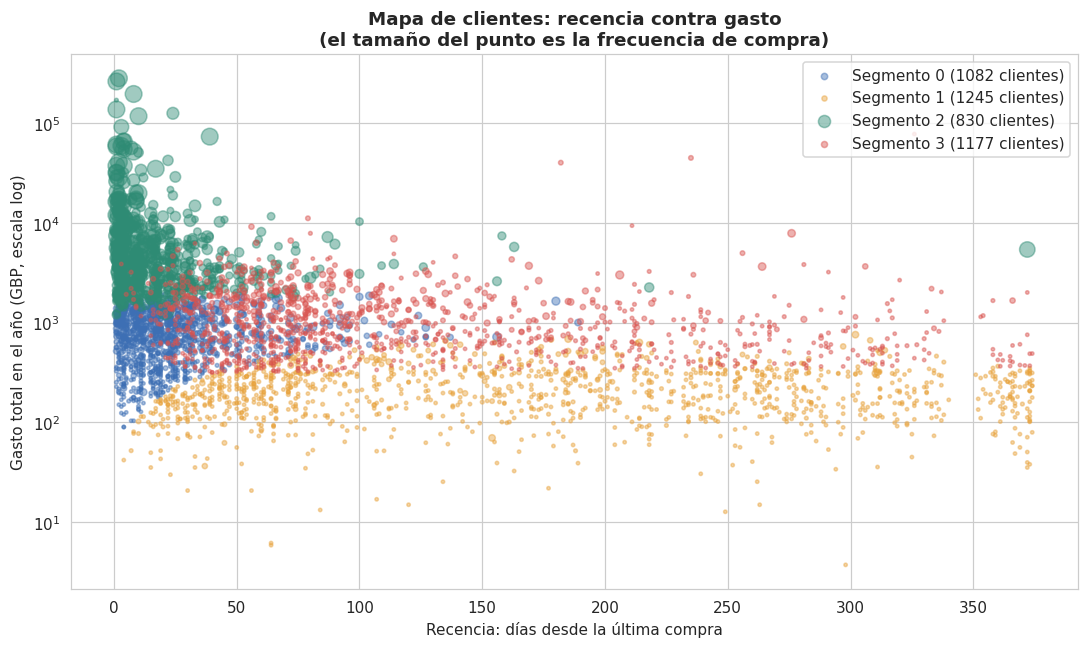

In [31]:
# Mapa del negocio: dónde cae cada segmento en el plano recencia-gasto
fig, ax = plt.subplots(figsize=(10, 6))
colores_seg = {0: '#3D6FB4', 1: '#E8A33D', 2: '#2E8B74', 3: '#D9534F'}
for s in sorted(clientes['segmento'].unique()):
    sub = clientes[clientes['segmento'] == s]
    ax.scatter(sub['recencia'], sub['monetario'],
               s=np.clip(sub['frecuencia'] * 3, 5, 120), alpha=0.45,
               color=colores_seg[s], label=f'Segmento {s} ({len(sub)} clientes)')
ax.set_yscale('log')
ax.set_xlabel('Recencia: días desde la última compra')
ax.set_ylabel('Gasto total en el año (GBP, escala log)')
ax.set_title('Mapa de clientes: recencia contra gasto\n(el tamaño del punto es la frecuencia de compra)',
             fontweight='bold')
ax.legend(markerscale=1, loc='upper right')
plt.tight_layout()
plt.savefig('fig/f14_mapa_segmentos.png', bbox_inches='tight')
plt.show()

## Validación con clústering jerárquico

El Caso 10 valida su resultado corriendo un segundo algoritmo con una lógica distinta y comparando.
Si dos métodos que no se parecen en nada llegan a la misma división, la estructura probablemente es
real y no un artefacto del método.

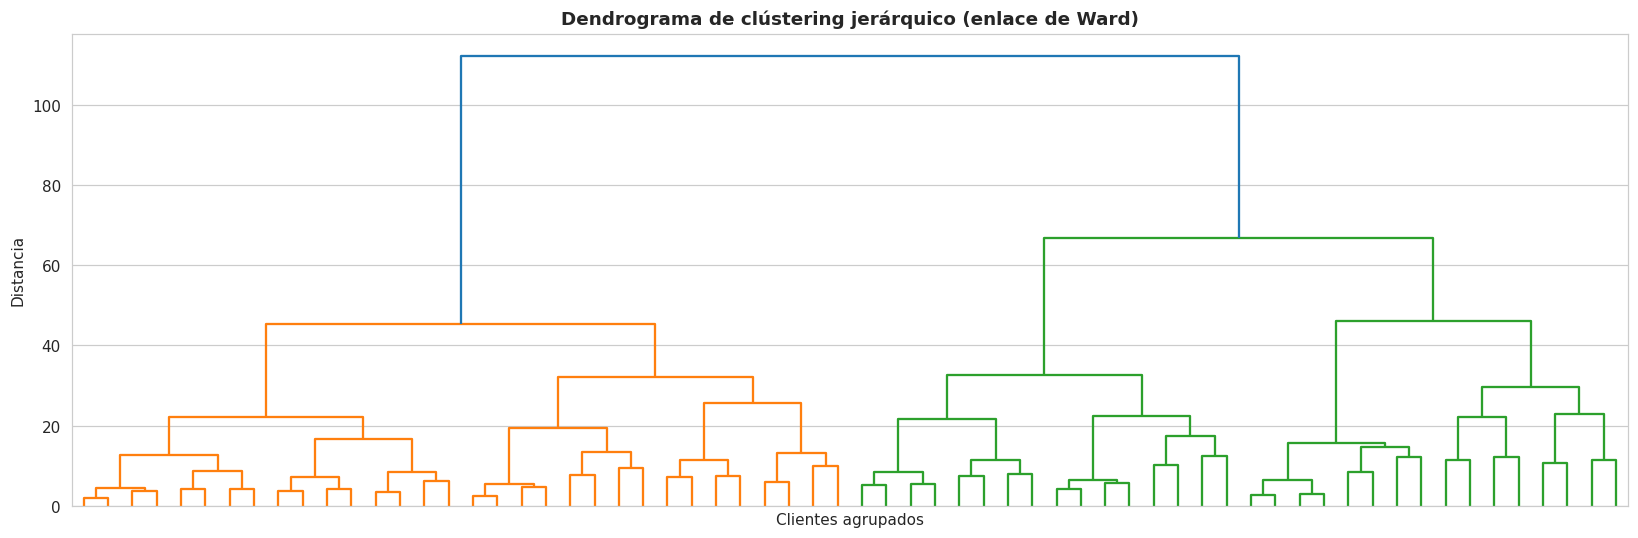

In [32]:
# Dendrograma con enlace de Ward, igual que en el Caso 10
Z = linkage(X, method='ward')

plt.figure(figsize=(15, 5))
dendrogram(Z, truncate_mode='level', p=5, color_threshold=None, no_labels=True)
plt.title('Dendrograma de clústering jerárquico (enlace de Ward)', fontweight='bold')
plt.xlabel('Clientes agrupados')
plt.ylabel('Distancia')
plt.tight_layout()
plt.savefig('fig/f08_dendrograma.png', bbox_inches='tight')
plt.show()

In [33]:
# Cortamos el dendrograma en el mismo número de grupos y comparamos
agglo = AgglomerativeClustering(n_clusters=K)
clientes['segmento_jerarquico'] = agglo.fit_predict(X)

cruce = pd.crosstab(clientes['segmento'], clientes['segmento_jerarquico'],
                    rownames=['K-means'], colnames=['jerárquico'])
print(cruce.to_string())

coincidencia = cruce.max(axis=1).sum() / len(clientes) * 100
print(f'\nClientes que ambos algoritmos ponen en el mismo grupo: {coincidencia:.1f}%')

RES['coincidencia_jerarquico'] = round(float(coincidencia), 1)
RES['cruce_jerarquico'] = cruce.values.tolist()

jerárquico     0    1    2    3
K-means                        
0            275  162   86  559
1           1245    0    0    0
2              0   57  753   20
3            509  625   15   28

Clientes que ambos algoritmos ponen en el mismo grupo: 73.4%


---
# PARTE 6 — Transacciones anómalas (segunda pregunta de la guía)

La segunda pregunta pide detectar transacciones raras. Acá se usa **Isolation Forest**, el algoritmo
del Caso 10: no necesita saber qué es una anomalía, solo cuántas esperar, y aísla los puntos que se
separan del resto con pocos cortes.

Una diferencia importante con la Parte 5: este análisis se hace sobre **todas las líneas de venta**,
incluyendo las 135.080 que no tienen cliente identificado. Para detectar una transacción rara no
hace falta saber quién la hizo.

In [34]:
# Variables de la transacción: cantidad, precio unitario y valor total, en logaritmo
trans = ventas.dropna(subset=['Description']).copy()
trans = trans[(trans['Quantity'] > 0) & (trans['UnitPrice'] > 0)]

X_trans = np.log1p(trans[['Quantity', 'UnitPrice', 'valor']].values)
print('Transacciones evaluadas:', f'{len(trans):,}')

Transacciones evaluadas: 522,504


El único parámetro que hay que fijar es la **contaminación**, es decir, qué proporción de casos raros
se espera encontrar. No es un valor que el algoritmo descubra: se le indica. Como la rúbrica pide un
ajuste cuidadoso de parámetros, conviene probar varios valores antes de decidir y mirar **qué agrega
cada escalón**, en vez de fijar uno de entrada.

In [35]:
# Probamos tres niveles de contaminación y miramos qué tipo de línea agrega cada uno
comparacion = []
marcas = {}
for c in [0.005, 0.01, 0.02, 0.05]:
    modelo = IsolationForest(contamination=c, random_state=42)
    marcas[c] = modelo.fit_predict(X_trans) == -1
    sel = trans[marcas[c]]
    comparacion.append({
        'contaminación': f'{c:.1%}',
        'líneas marcadas': int(marcas[c].sum()),
        '% del valor': round(float(sel['valor'].sum() / trans['valor'].sum() * 100), 1),
        'mediana cantidad': float(sel['Quantity'].median()),
        'mediana valor (GBP)': round(float(sel['valor'].median()), 1),
    })

comp_cont = pd.DataFrame(comparacion)
print(comp_cont.to_string(index=False))

# ¿Qué agrega cada escalón respecto del anterior?
print('\nLo que agrega cada escalón respecto del nivel anterior:')
niveles = [0.005, 0.01, 0.02, 0.05]
for a, b in zip(niveles, niveles[1:]):
    nuevas = trans[marcas[b] & ~marcas[a]]
    print(f'  de {a:.1%} a {b:.1%}: +{len(nuevas):,} líneas | '
          f'mediana cantidad {nuevas["Quantity"].median():.0f} unidades | '
          f'mediana valor GBP {nuevas["valor"].median():.0f}')

RES['barrido_contaminacion'] = comp_cont.to_dict('records')

contaminación  líneas marcadas  % del valor  mediana cantidad  mediana valor (GBP)
         0.5%             2612         17.7             240.0                403.2
         1.0%             5132         22.7             150.0                275.4
         2.0%            10447         29.2              96.0                179.0
         5.0%            26052         38.7              44.0                 92.5

Lo que agrega cada escalón respecto del nivel anterior:
  de 0.5% a 1.0%: +2,520 líneas | mediana cantidad 96 unidades | mediana valor GBP 204
  de 1.0% a 2.0%: +5,315 líneas | mediana cantidad 72 unidades | mediana valor GBP 150
  de 2.0% a 5.0%: +15,605 líneas | mediana cantidad 24 unidades | mediana valor GBP 53


La tabla muestra por qué **1 %** es la elección adecuada. Al pasar del 1 % al 2 % las líneas que se
agregan siguen siendo pedidos genuinamente grandes, pero al llegar al 5 % la mediana de lo que entra
cae a niveles que ya son compras mayoristas corrientes: el modelo empezaría a marcar *"cliente
grande"* como *"transacción anómala"*, que no es lo que se busca. Se trabaja entonces con
contaminación del 1 %.

In [36]:
iso_t = IsolationForest(contamination=0.01, random_state=42)
trans['anomala'] = iso_t.fit_predict(X_trans) == -1

n_anom = int(trans['anomala'].sum())
print(f'Transacciones marcadas como anómalas: {n_anom:,} ({n_anom/len(trans)*100:.2f}%)')
print(f'Valor que mueven: GBP {trans.loc[trans["anomala"], "valor"].sum():,.0f} '
      f'({trans.loc[trans["anomala"], "valor"].sum()/trans["valor"].sum()*100:.1f}% del total)')

RES['n_transacciones_evaluadas'] = int(len(trans))
RES['n_transacciones_anomalas'] = n_anom
RES['valor_transacciones_anomalas'] = round(float(trans.loc[trans['anomala'], 'valor'].sum()), 0)
RES['pct_valor_anomalas'] = round(float(
    trans.loc[trans['anomala'], 'valor'].sum() / trans['valor'].sum() * 100), 1)

Transacciones marcadas como anómalas: 5,132 (0.98%)
Valor que mueven: GBP 2,330,887 (22.7% del total)


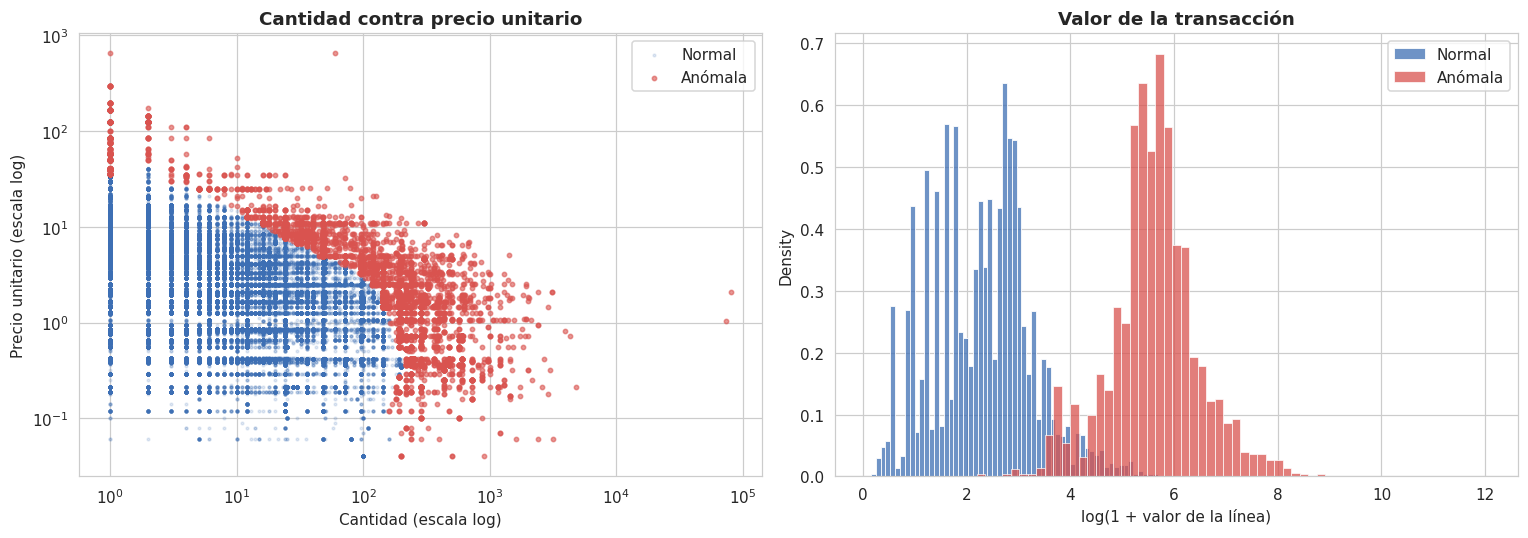

In [37]:
# Dónde caen las transacciones anómalas dentro de la nube de datos
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

normal = trans[~trans['anomala']]
rara = trans[trans['anomala']]

ax[0].scatter(normal['Quantity'], normal['UnitPrice'], s=3, alpha=0.15,
              color='#3D6FB4', label='Normal')
ax[0].scatter(rara['Quantity'], rara['UnitPrice'], s=8, alpha=0.6,
              color='#D9534F', label='Anómala')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('Cantidad (escala log)'); ax[0].set_ylabel('Precio unitario (escala log)')
ax[0].set_title('Cantidad contra precio unitario', fontweight='bold')
ax[0].legend()

sns.histplot(np.log1p(normal['valor']), bins=60, ax=ax[1], color='#3D6FB4',
             stat='density', label='Normal')
sns.histplot(np.log1p(rara['valor']), bins=60, ax=ax[1], color='#D9534F',
             stat='density', label='Anómala')
ax[1].set_xlabel('log(1 + valor de la línea)')
ax[1].set_title('Valor de la transacción', fontweight='bold')
ax[1].legend()

plt.tight_layout()
plt.savefig('fig/f09_transacciones_anomalas.png', bbox_inches='tight')
plt.show()

In [38]:
# ¿Qué tienen de raro? Comparamos las anómalas contra las normales
comp = pd.DataFrame({
    'Normales': normal[['Quantity', 'UnitPrice', 'valor']].median(),
    'Anómalas': rara[['Quantity', 'UnitPrice', 'valor']].median(),
}).round(2)
comp['Veces'] = (comp['Anómalas'] / comp['Normales']).round(1)
print(comp.to_string())

print('\nLas 8 transacciones más grandes marcadas como anómalas:')
cols = ['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'valor', 'Country']
print(rara.nlargest(8, 'valor')[cols].to_string(index=False))

RES['comp_anomalas'] = {k: {kk: float(vv) for kk, vv in v.items()} for k, v in comp.items()}
RES['top_anomalas'] = rara.nlargest(6, 'valor')[
    ['InvoiceNo', 'Description', 'Quantity', 'UnitPrice', 'valor']
].round(2).to_dict('records')

           Normales  Anómalas  Veces
Quantity       3.00    150.00   50.0
UnitPrice      2.08      2.69    1.3
valor          9.90    275.40   27.8

Las 8 transacciones más grandes marcadas como anómalas:
InvoiceNo                         Description  Quantity  UnitPrice     valor        Country
   581483         PAPER CRAFT , LITTLE BIRDIE     80995       2.08 168469.60 United Kingdom
   541431      MEDIUM CERAMIC TOP STORAGE JAR     74215       1.04  77183.60 United Kingdom
   556444      PICNIC BASKET WICKER 60 PIECES        60     649.50  38970.00 United Kingdom
   567423 SET OF TEA COFFEE SUGAR TINS PANTRY      1412       5.06   7144.72 United Kingdom
   540815  FAIRY CAKE FLANNEL ASSORTED COLOUR      3114       2.10   6539.40 United Kingdom
   550461  FAIRY CAKE FLANNEL ASSORTED COLOUR      3114       2.10   6539.40 United Kingdom
   573003                  RABBIT NIGHT LIGHT      2400       2.08   4992.00    Netherlands
   540815  WHITE HANGING HEART T-LIGHT HOLDER      1930    

In [39]:
# ¿Las anómalas son sobre todo pedidos gigantes o productos carísimos?
grandes = rara[rara['Quantity'] >= rara['Quantity'].median()]
caras = rara[rara['UnitPrice'] >= rara['UnitPrice'].median()]

print(f"Anómalas con cantidad por encima de 1.000 unidades : "
      f"{int((rara['Quantity'] > 1000).sum()):,}")
print(f"Anómalas con precio unitario mayor a GBP 100       : "
      f"{int((rara['UnitPrice'] > 100).sum()):,}")
print(f"Anómalas con valor de línea mayor a GBP 1.000      : "
      f"{int((rara['valor'] > 1000).sum()):,}")

RES['anom_cant_alta'] = int((rara['Quantity'] > 1000).sum())
RES['anom_precio_alto'] = int((rara['UnitPrice'] > 100).sum())
RES['anom_valor_alto'] = int((rara['valor'] > 1000).sum())

Anómalas con cantidad por encima de 1.000 unidades : 104
Anómalas con precio unitario mayor a GBP 100       : 114
Anómalas con valor de línea mayor a GBP 1.000      : 334


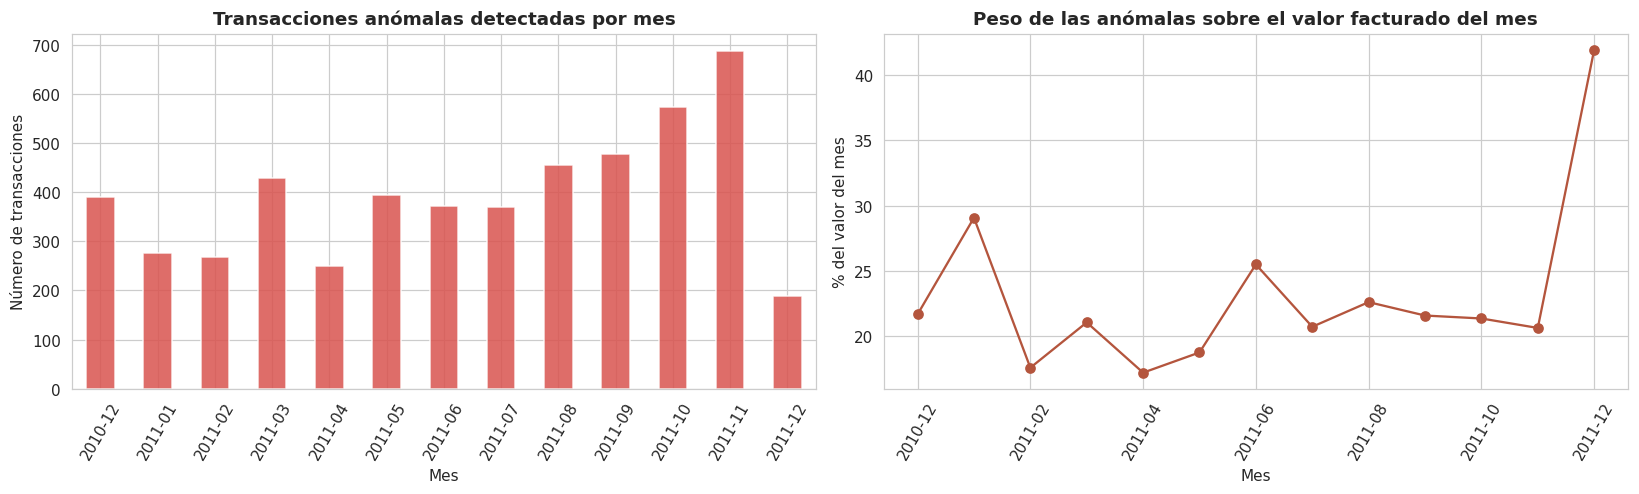

             total   anomalo  n_anom  % del valor
mes                                              
2010-12   775572.2  167814.0     390         21.6
2011-01   670362.0  194794.1     277         29.1
2011-02   507783.4   89054.2     268         17.5
2011-03   689708.5  144976.8     429         21.0
2011-04   515354.8   88422.7     249         17.2
2011-05   739914.4  138442.2     394         18.7
2011-06   737559.0  187872.6     372         25.5
2011-07   688144.8  142329.2     370         20.7
2011-08   724196.8  163501.7     455         22.6
2011-09  1028313.8  221570.5     478         21.5
2011-10  1103311.0  235227.4     573         21.3
2011-11  1452112.7  299035.8     688         20.6
2011-12   614487.6  257845.3     189         42.0


In [40]:
# ¿Cuándo aparecen las anomalías y cuánto pesan mes a mes?
trans['mes'] = trans['InvoiceDate'].dt.to_period('M').astype(str)
por_mes = trans.groupby('mes').agg(
    total=('valor', 'sum'),
    anomalo=('valor', lambda x: x[trans.loc[x.index, 'anomala']].sum()),
    n_anom=('anomala', 'sum'),
)
por_mes['% del valor'] = por_mes['anomalo'] / por_mes['total'] * 100

fig, ax = plt.subplots(1, 2, figsize=(15, 4.6))
(por_mes['n_anom']).plot(kind='bar', ax=ax[0], color='#D9534F', alpha=0.85)
ax[0].set_title('Transacciones anómalas detectadas por mes', fontweight='bold')
ax[0].set_xlabel('Mes'); ax[0].set_ylabel('Número de transacciones')
ax[0].tick_params(axis='x', rotation=60)

por_mes['% del valor'].plot(kind='line', marker='o', ax=ax[1], color='#B4553D')
ax[1].set_title('Peso de las anómalas sobre el valor facturado del mes', fontweight='bold')
ax[1].set_xlabel('Mes'); ax[1].set_ylabel('% del valor del mes')
ax[1].tick_params(axis='x', rotation=60)

plt.tight_layout()
plt.savefig('fig/f15_anomalias_mes.png', bbox_inches='tight')
plt.show()

print(por_mes.round(1).to_string())
RES['mes_mas_anomalias'] = str(por_mes['n_anom'].idxmax())
RES['pct_valor_anom_max'] = round(float(por_mes['% del valor'].max()), 1)
RES['mes_pct_max'] = str(por_mes['% del valor'].idxmax())

---
# PARTE 7 — Clientes atípicos (tercera pregunta de la guía)

La tercera pregunta es distinta de la segunda: una transacción rara puede ser un pedido grande y
perfectamente legítimo, mientras que un **cliente** atípico es alguien cuyo comportamiento completo
—cuánto compra, cada cuánto, cuánto devuelve— se sale del molde. Por eso se corre un segundo
Isolation Forest, ahora sobre la tabla de clientes.

In [41]:
# Sobre las variables del cliente, incluyendo la tasa de devolución
vars_anom = ['recencia', 'frecuencia', 'monetario', 'ticket_promedio',
             'productos_distintos', 'tasa_devolucion']
X_cli = StandardScaler().fit_transform(np.log1p(clientes[vars_anom]))

iso_c = IsolationForest(contamination=0.05, random_state=42)
clientes['atipico'] = iso_c.fit_predict(X_cli) == -1

n_at = int(clientes['atipico'].sum())
print(f'Clientes atípicos: {n_at} de {len(clientes):,} ({n_at/len(clientes)*100:.1f}%)')
print(f'Facturan GBP {clientes.loc[clientes["atipico"], "monetario"].sum():,.0f} '
      f'({clientes.loc[clientes["atipico"], "monetario"].sum()/clientes["monetario"].sum()*100:.1f}% '
      f'de la venta)')

RES['n_clientes_atipicos'] = n_at
RES['pct_venta_atipicos'] = round(float(
    clientes.loc[clientes['atipico'], 'monetario'].sum() / clientes['monetario'].sum() * 100), 1)

Clientes atípicos: 217 de 4,334 (5.0%)
Facturan GBP 3,671,710 (42.0% de la venta)


In [42]:
# En qué se diferencian de los demás
comp_cli = pd.DataFrame({
    'Normales': clientes.loc[~clientes['atipico'], vars_anom].median(),
    'Atípicos': clientes.loc[clientes['atipico'], vars_anom].median(),
}).round(2)
print(comp_cli.to_string())

print('\nCómo se reparten los clientes atípicos entre los segmentos:')
rep = pd.crosstab(clientes['segmento'], clientes['atipico'],
                  rownames=['segmento'], colnames=['atípico'])
rep['% atípicos'] = (rep[True] / (rep[True] + rep[False]) * 100).round(1)
print(rep.to_string())

RES['comp_clientes_atipicos'] = {k: {kk: float(vv) for kk, vv in v.items()}
                                 for k, v in comp_cli.items()}
RES['atipicos_por_segmento'] = {int(i): float(r['% atípicos']) for i, r in rep.iterrows()}

                     Normales  Atípicos
recencia                52.00     15.00
frecuencia               2.00      6.00
monetario              643.76   4959.10
ticket_promedio        285.56    450.60
productos_distintos     35.00     45.00
tasa_devolucion          0.00      2.42

Cómo se reparten los clientes atípicos entre los segmentos:
atípico   False  True  % atípicos
segmento                         
0          1067    15         1.4
1          1195    50         4.0
2           712   118        14.2
3          1143    34         2.9


In [43]:
# Los dos perfiles opuestos de cliente atípico
mayoristas = clientes[clientes['atipico'] & (clientes['monetario'] >
                                             clientes['monetario'].quantile(0.95))]
devolvedores = clientes[clientes['atipico'] & (clientes['tasa_devolucion'] > 50)]

print(f'Atípicos por volumen (gasto en el 5% más alto): {len(mayoristas)}')
print(f'Atípicos por devolución (devuelven más de la mitad): {len(devolvedores)}')
print()
print('Los 6 clientes que más gastaron:')
print(clientes.nlargest(6, 'monetario')[
    ['recencia', 'frecuencia', 'monetario', 'ticket_promedio', 'tasa_devolucion',
     'segmento', 'atipico']].round(1).to_string())

RES['n_atipicos_volumen'] = int(len(mayoristas))
RES['n_atipicos_devolucion'] = int(len(devolvedores))
RES['top_clientes'] = clientes.nlargest(5, 'monetario')[
    ['recencia', 'frecuencia', 'monetario', 'tasa_devolucion', 'segmento', 'atipico']
].round(1).reset_index().to_dict('records')

Atípicos por volumen (gasto en el 5% más alto): 104
Atípicos por devolución (devuelven más de la mitad): 2

Los 6 clientes que más gastaron:
            recencia  frecuencia  monetario  ticket_promedio  tasa_devolucion  segmento  atipico
CustomerID                                                                                      
14646              2          72   279138.0           3876.9              0.1         2     True
18102              1          60   259657.3           4327.6              0.0         2     True
17450              8          46   194390.8           4225.9              2.4         2     True
16446              1           2   168472.5          84236.2             50.0         2     True
14911              1         198   136161.8            687.7              5.2         2     True
12415             24          20   124564.5           6228.2              0.7         2     True


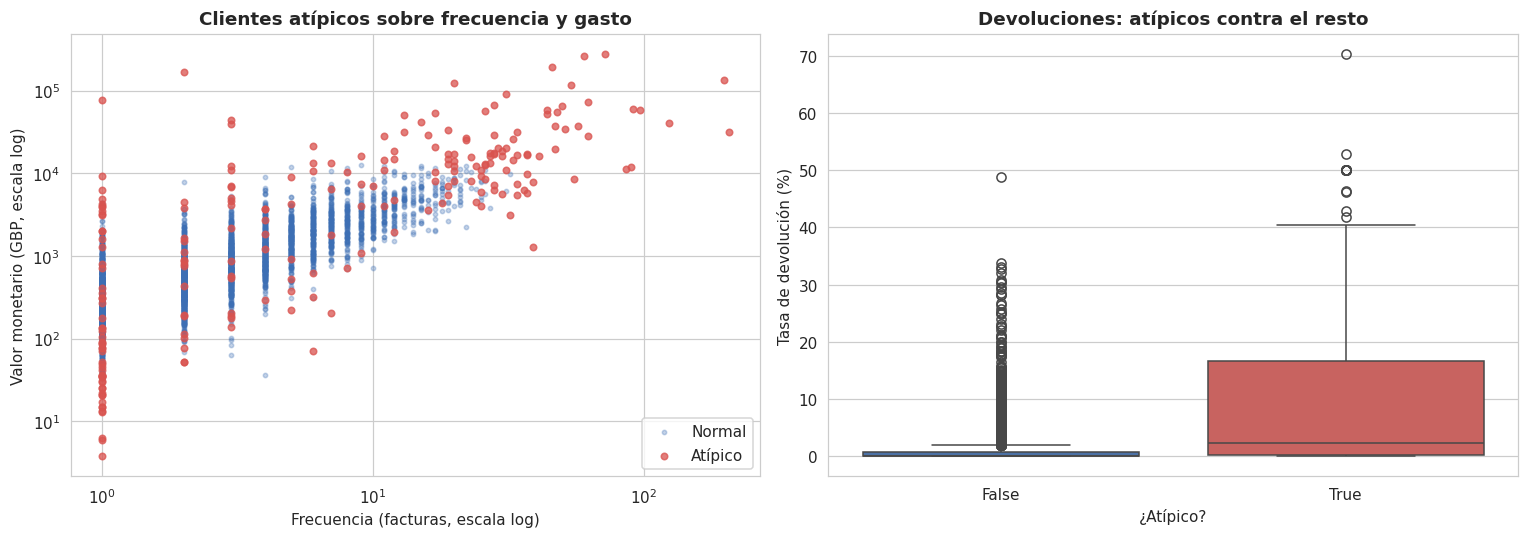

In [44]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

ax[0].scatter(clientes.loc[~clientes['atipico'], 'frecuencia'],
              clientes.loc[~clientes['atipico'], 'monetario'],
              s=8, alpha=0.3, color='#3D6FB4', label='Normal')
ax[0].scatter(clientes.loc[clientes['atipico'], 'frecuencia'],
              clientes.loc[clientes['atipico'], 'monetario'],
              s=18, alpha=0.75, color='#D9534F', label='Atípico')
ax[0].set_xscale('log'); ax[0].set_yscale('log')
ax[0].set_xlabel('Frecuencia (facturas, escala log)')
ax[0].set_ylabel('Valor monetario (GBP, escala log)')
ax[0].set_title('Clientes atípicos sobre frecuencia y gasto', fontweight='bold')
ax[0].legend()

sns.boxplot(x=clientes['atipico'], y=clientes['tasa_devolucion'],
            hue=clientes['atipico'], ax=ax[1], legend=False, palette=['#3D6FB4', '#D9534F'])
ax[1].set_xlabel('¿Atípico?')
ax[1].set_ylabel('Tasa de devolución (%)')
ax[1].set_title('Devoluciones: atípicos contra el resto', fontweight='bold')

plt.tight_layout()
plt.savefig('fig/f10_clientes_atipicos.png', bbox_inches='tight')
plt.show()

## Validación visual de la segmentación con PCA y t-SNE

Las variables del modelo son cuatro, así que los grupos viven en un espacio de cuatro dimensiones
que no se puede dibujar. El Caso 10 resuelve esto igual: se reduce a dos dimensiones con PCA y con
t-SNE y se colorea por clúster. Si los colores quedan separados, la agrupación captó estructura real.

In [45]:
pca = PCA(n_components=2)
coords_pca = pca.fit_transform(X)
print('Varianza explicada por las 2 primeras componentes:',
      f'{pca.explained_variance_ratio_.sum():.1%}')
print('Por componente:', pca.explained_variance_ratio_.round(4))

cargas = pd.DataFrame(pca.components_.round(3), columns=vars_modelo, index=['PC1', 'PC2'])
print('\nCargas:')
print(cargas.to_string())

RES['pca_var'] = round(float(pca.explained_variance_ratio_.sum()), 4)
RES['pca_cargas'] = cargas.to_dict()

Varianza explicada por las 2 primeras componentes: 88.1%
Por componente: [0.6243 0.2563]

Cargas:
     recencia  frecuencia  monetario  ticket_promedio
PC1    -0.435       0.538      0.612            0.383
PC2     0.510      -0.353      0.197            0.759


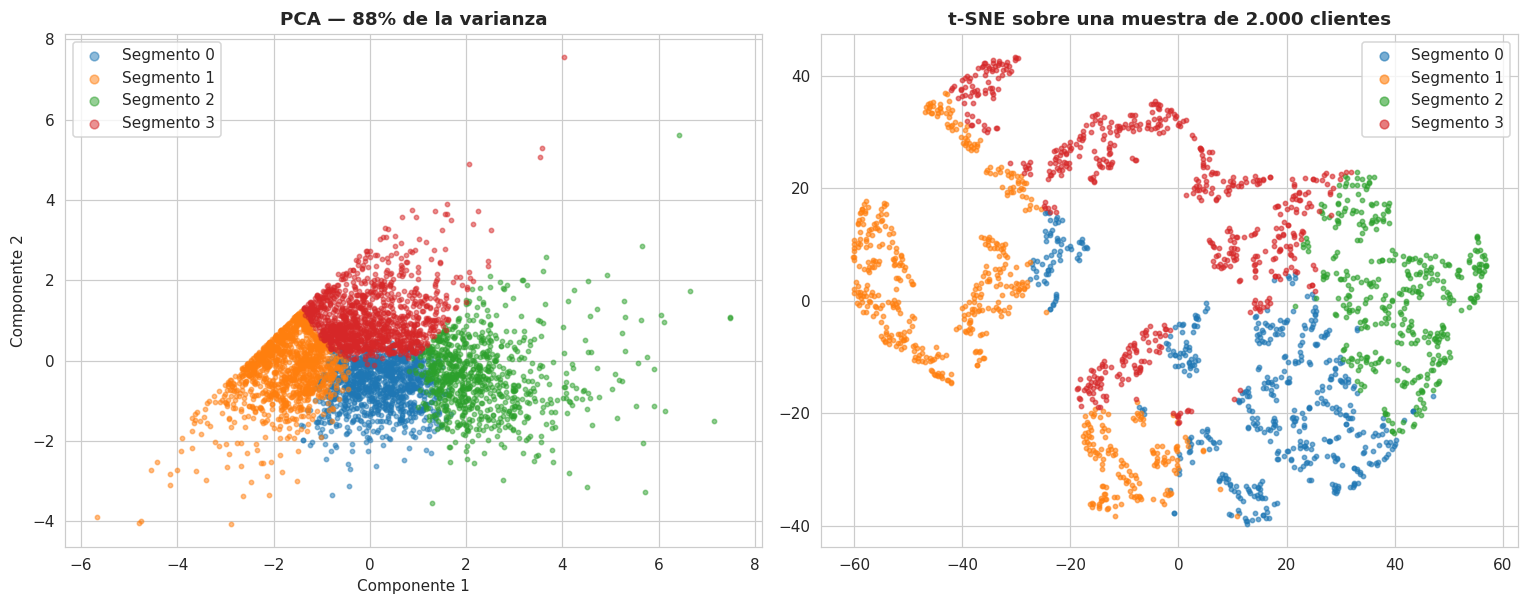

In [46]:
# t-SNE sobre una muestra, que es costoso; el Caso 10 lo usa igual como validación
muestra = np.random.RandomState(42).choice(len(X), size=min(2000, len(X)), replace=False)
coords_tsne = TSNE(n_components=2, random_state=42, init='pca',
                   perplexity=30).fit_transform(X[muestra])

fig, ax = plt.subplots(1, 2, figsize=(14, 5.6))
for s in sorted(clientes['segmento'].unique()):
    m = clientes['segmento'].values == s
    ax[0].scatter(coords_pca[m, 0], coords_pca[m, 1], s=8, alpha=0.5, label=f'Segmento {s}')
ax[0].set_title(f'PCA — {pca.explained_variance_ratio_.sum():.0%} de la varianza',
                fontweight='bold')
ax[0].set_xlabel('Componente 1'); ax[0].set_ylabel('Componente 2')
ax[0].legend(markerscale=2)

seg_m = clientes['segmento'].values[muestra]
for s in sorted(clientes['segmento'].unique()):
    m = seg_m == s
    ax[1].scatter(coords_tsne[m, 0], coords_tsne[m, 1], s=8, alpha=0.6, label=f'Segmento {s}')
ax[1].set_title('t-SNE sobre una muestra de 2.000 clientes', fontweight='bold')
ax[1].legend(markerscale=2)

plt.tight_layout()
plt.savefig('fig/f11_pca_tsne.png', bbox_inches='tight')
plt.show()

---
# PARTE 8 — Respuestas a las preguntas de la guía

In [47]:
# Resumen final con todo lo que responde a las tres preguntas
print('PREGUNTA 1 — ¿Se pueden segmentar los clientes por transacciones y valor gastado?')
print(f"   Sí. {len(clientes):,} clientes quedaron repartidos en {K} segmentos.")
print(f"   Silueta {sil_final:.3f} y Calinski-Harabasz {ch_final:.0f}.")
print(f"   El clústering jerárquico coincide en el {RES['coincidencia_jerarquico']}% de los casos.")
print()
print('PREGUNTA 2 — ¿Se pueden identificar transacciones anómalas?')
print(f"   Sí. {n_anom:,} transacciones de {len(trans):,} ({n_anom/len(trans)*100:.2f}%),")
print(f"   que mueven GBP {trans.loc[trans['anomala'], 'valor'].sum():,.0f}.")
print()
print('PREGUNTA 3 — ¿Se pueden identificar clientes atípicos?')
print(f"   Sí. {n_at} clientes ({n_at/len(clientes)*100:.1f}%),")
print(f"   que concentran el {RES['pct_venta_atipicos']}% de la venta.")

PREGUNTA 1 — ¿Se pueden segmentar los clientes por transacciones y valor gastado?
   Sí. 4,334 clientes quedaron repartidos en 4 segmentos.
   Silueta 0.276 y Calinski-Harabasz 2226.
   El clústering jerárquico coincide en el 73.4% de los casos.

PREGUNTA 2 — ¿Se pueden identificar transacciones anómalas?
   Sí. 5,132 transacciones de 522,504 (0.98%),
   que mueven GBP 2,330,887.

PREGUNTA 3 — ¿Se pueden identificar clientes atípicos?
   Sí. 217 clientes (5.0%),
   que concentran el 42.0% de la venta.


---
# PARTE 9 — Reducción de dimensionalidad y modelos alternativos

Hasta acá PCA se usó únicamente para **dibujar** los segmentos. Pero en el Caso 9 el análisis de
componentes principales cumple un segundo papel: se usa para **transformar el espacio antes de
agrupar**, y después se vuelve a correr K-means sobre las componentes para ver si el resultado se
sostiene. Esta parte replica ese procedimiento y agrega el otro algoritmo de agrupación de la
unidad, **DBSCAN**, que trabaja con una lógica completamente distinta a la de K-means.

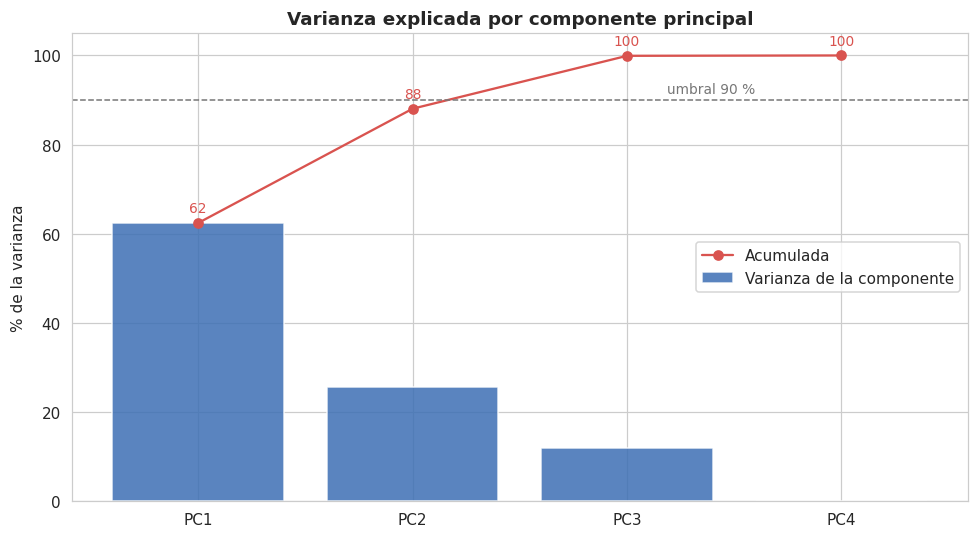

Varianza por componente (%): [62.4 25.6 11.9  0.1]
Acumulada (%)             : [ 62.4  88.1  99.9 100. ]


In [48]:
# Varianza explicada: ¿cuántas componentes hacen falta para representar a los clientes?
pca_full = PCA()
pca_full.fit(X)

var = pca_full.explained_variance_ratio_ * 100
acum = var.cumsum()

fig, ax = plt.subplots(figsize=(9, 5))
ax.bar(range(1, len(var) + 1), var, color='#3D6FB4', alpha=0.85, label='Varianza de la componente')
ax.plot(range(1, len(acum) + 1), acum, marker='o', color='#D9534F', label='Acumulada')
ax.axhline(90, ls='--', color='#777777', linewidth=1)
ax.text(len(var) - 0.4, 91.5, 'umbral 90 %', color='#777777', fontsize=9, ha='right')
for i, (v, a) in enumerate(zip(var, acum), start=1):
    ax.annotate(f'{a:.0f}', xy=(i, a), xytext=(0, 7), textcoords='offset points',
                ha='center', fontsize=9, color='#D9534F')
ax.set_xticks(range(1, len(var) + 1))
ax.set_xticklabels([f'PC{i}' for i in range(1, len(var) + 1)])
ax.set_ylabel('% de la varianza')
ax.set_title('Varianza explicada por componente principal', fontweight='bold')
ax.legend(loc='center right')
plt.tight_layout()
plt.savefig('fig/f16_varianza_pca.png', bbox_inches='tight')
plt.show()

print('Varianza por componente (%):', var.round(1))
print('Acumulada (%)             :', acum.round(1))
RES['pca_var_comp'] = [round(float(v), 1) for v in var]
RES['pca_var_acum'] = [round(float(a), 1) for a in acum]

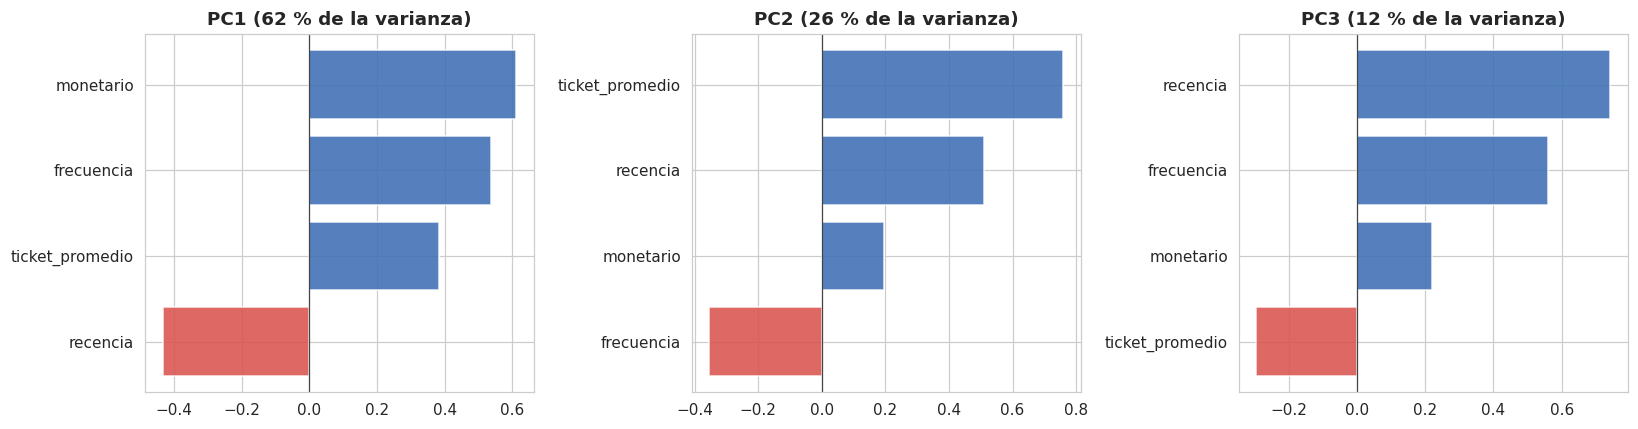

                   PC1    PC2    PC3
recencia        -0.435  0.510  0.742
frecuencia       0.538 -0.353  0.561
monetario        0.612  0.197  0.219
ticket_promedio  0.383  0.759 -0.294


In [49]:
# ¿Qué significa cada componente? Las cargas lo dicen
cargas = pd.DataFrame(pca_full.components_[:3].T, index=vars_modelo,
                      columns=['PC1', 'PC2', 'PC3'])

fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for j, comp in enumerate(['PC1', 'PC2', 'PC3']):
    orden = cargas[comp].sort_values()
    colores_c = ['#D9534F' if v < 0 else '#3D6FB4' for v in orden]
    ax[j].barh(orden.index, orden.values, color=colores_c, alpha=0.88)
    ax[j].axvline(0, color='#444444', linewidth=0.8)
    ax[j].set_title(f'{comp} ({var[j]:.0f} % de la varianza)', fontweight='bold')
plt.tight_layout()
plt.savefig('fig/f17_cargas_pca.png', bbox_inches='tight')
plt.show()

print(cargas.round(3).to_string())
RES['cargas_pca'] = cargas.round(3).to_dict()

In [50]:
# Igual que el Caso 9: repetir K-means sobre las componentes principales
n_comp = int(np.argmax(acum >= 90) + 1)
print(f'Con {n_comp} componentes se conserva el {acum[n_comp-1]:.1f} % de la varianza')

X_pca = PCA(n_components=n_comp).fit_transform(X)
kmeans_pca = KMeans(n_clusters=K, n_init='auto', random_state=42)
seg_pca = kmeans_pca.fit_predict(X_pca)

sil_pca = silhouette_score(X_pca, seg_pca)
print(f'Silueta sobre las componentes : {sil_pca:.4f}')
print(f'Silueta del modelo original   : {sil_final:.4f}')
print()

cruce_pca = pd.crosstab(clientes['segmento'], seg_pca,
                        rownames=['modelo original'], colnames=['sobre componentes'])
print(cruce_pca.to_string())
coinc_pca = cruce_pca.max(axis=1).sum() / len(clientes) * 100
print(f'\nClientes que caen en el mismo grupo: {coinc_pca:.1f}%')

RES['n_comp_90'] = n_comp
RES['silueta_pca'] = round(float(sil_pca), 4)
RES['coincidencia_pca'] = round(float(coinc_pca), 1)

Con 3 componentes se conserva el 99.9 % de la varianza


Silueta sobre las componentes : 0.2754
Silueta del modelo original   : 0.2760

sobre componentes     0     1     2    3
modelo original                         
0                  1067    12     3    0
1                     0  1232    13    0
2                    12     0     0  818
3                    14     0  1158    5

Clientes que caen en el mismo grupo: 98.6%


## DBSCAN: el otro algoritmo de agrupación de la unidad

El Caso 9 introduce **DBSCAN**, que agrupa de una forma radicalmente distinta a K-means. En lugar de
pedirle un número de grupos, se le indican dos cosas: `eps`, el radio dentro del cual dos puntos se
consideran vecinos, y `min_samples`, cuántos vecinos hacen falta para formar un núcleo. El algoritmo
decide solo cuántos grupos hay y, además, tiene algo que K-means no tiene: puede declarar puntos
como **ruido**, sin asignarlos a ningún grupo.

In [51]:
# Barrido de eps para encontrar un valor razonable
filas = []
for eps in [0.3, 0.4, 0.5, 0.6, 0.8, 1.0, 1.2, 1.5]:
    db = DBSCAN(eps=eps, min_samples=10).fit(X)
    etq = db.labels_
    n_grupos = len(set(etq)) - (1 if -1 in etq else 0)
    n_ruido = int((etq == -1).sum())
    filas.append({'eps': eps, 'grupos': n_grupos, 'ruido': n_ruido,
                  '% ruido': round(n_ruido / len(etq) * 100, 1),
                  'mayor grupo %': round(pd.Series(etq[etq != -1]).value_counts(normalize=True).max() * 100, 1)
                  if n_grupos > 0 else 0.0})

barrido = pd.DataFrame(filas)
print(barrido.to_string(index=False))
RES['barrido_dbscan'] = barrido.to_dict('records')

 eps  grupos  ruido  % ruido  mayor grupo %
 0.3      10   1007     23.2           41.2
 0.4       3    428      9.9           43.1
 0.5       3    232      5.4           44.7
 0.6       2    134      3.1           65.0
 0.8       1     62      1.4          100.0
 1.0       1     35      0.8          100.0
 1.2       1     17      0.4          100.0
 1.5       1      8      0.2          100.0


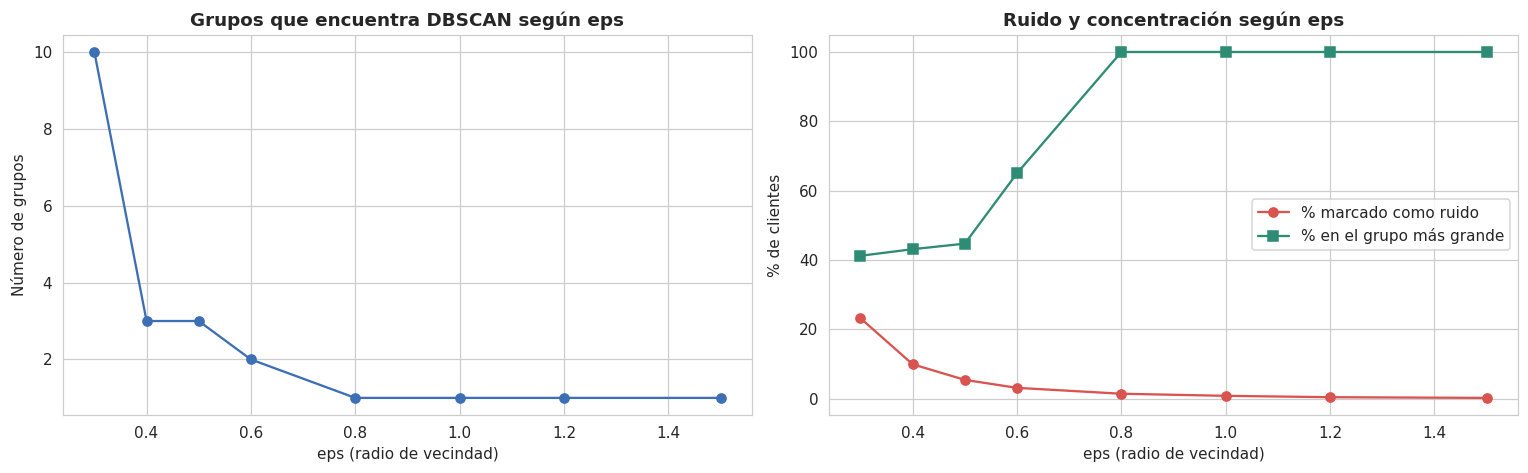

In [52]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.4))
ax[0].plot(barrido['eps'], barrido['grupos'], marker='o', color='#3D6FB4')
ax[0].set_title('Grupos que encuentra DBSCAN según eps', fontweight='bold')
ax[0].set_xlabel('eps (radio de vecindad)'); ax[0].set_ylabel('Número de grupos')

ax[1].plot(barrido['eps'], barrido['% ruido'], marker='o', color='#D9534F', label='% marcado como ruido')
ax[1].plot(barrido['eps'], barrido['mayor grupo %'], marker='s', color='#2E8B74',
           label='% en el grupo más grande')
ax[1].set_title('Ruido y concentración según eps', fontweight='bold')
ax[1].set_xlabel('eps (radio de vecindad)'); ax[1].set_ylabel('% de clientes')
ax[1].legend()
plt.tight_layout()
plt.savefig('fig/f18_dbscan_barrido.png', bbox_inches='tight')
plt.show()

In [53]:
# Nos quedamos con el eps que deja un porcentaje de ruido manejable
eps_elegido = 0.6
db = DBSCAN(eps=eps_elegido, min_samples=10).fit(X)
clientes['segmento_dbscan'] = db.labels_

n_grupos = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_ruido = int((db.labels_ == -1).sum())
print(f'DBSCAN con eps={eps_elegido}, min_samples=10')
print(f'  Grupos encontrados : {n_grupos}')
print(f'  Puntos como ruido  : {n_ruido:,} ({n_ruido/len(clientes)*100:.1f}%)')
print()
print('Tamaño de cada grupo:')
print(pd.Series(db.labels_).value_counts().sort_index().to_string())

RES['dbscan_eps'] = eps_elegido
RES['dbscan_grupos'] = int(n_grupos)
RES['dbscan_ruido'] = n_ruido
RES['dbscan_pct_ruido'] = round(n_ruido / len(clientes) * 100, 1)
RES['dbscan_mayor'] = round(float(pd.Series(db.labels_[db.labels_ != -1])
                                  .value_counts(normalize=True).max() * 100), 1)

DBSCAN con eps=0.6, min_samples=10
  Grupos encontrados : 2
  Puntos como ruido  : 134 (3.1%)

Tamaño de cada grupo:
-1     134
 0    2728
 1    1472


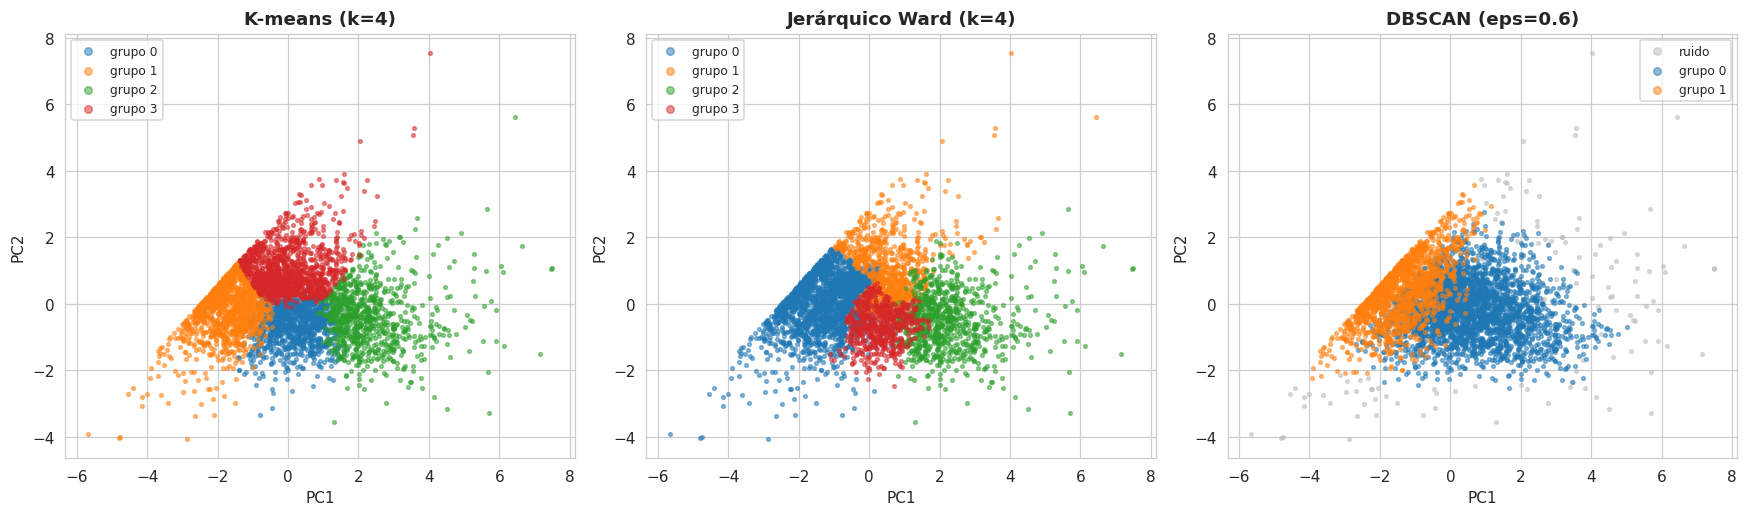

In [54]:
# Comparación visual de las tres agrupaciones sobre el mismo plano de PCA
coords = PCA(n_components=2).fit_transform(X)

fig, ax = plt.subplots(1, 3, figsize=(16, 4.8))
titulos = ['K-means (k=4)', 'Jerárquico Ward (k=4)', f'DBSCAN (eps={eps_elegido})']
etiquetas_list = [clientes['segmento'].values, clientes['segmento_jerarquico'].values, db.labels_]

for a, tit, etq in zip(ax, titulos, etiquetas_list):
    for v in sorted(set(etq)):
        m = etq == v
        color = '#BBBBBB' if v == -1 else None
        nombre = 'ruido' if v == -1 else f'grupo {v}'
        a.scatter(coords[m, 0], coords[m, 1], s=6, alpha=0.5, label=nombre, color=color)
    a.set_title(tit, fontweight='bold')
    a.set_xlabel('PC1'); a.set_ylabel('PC2')
    a.legend(markerscale=2, fontsize=8)

plt.tight_layout()
plt.savefig('fig/f19_comparacion_algoritmos.png', bbox_inches='tight')
plt.show()

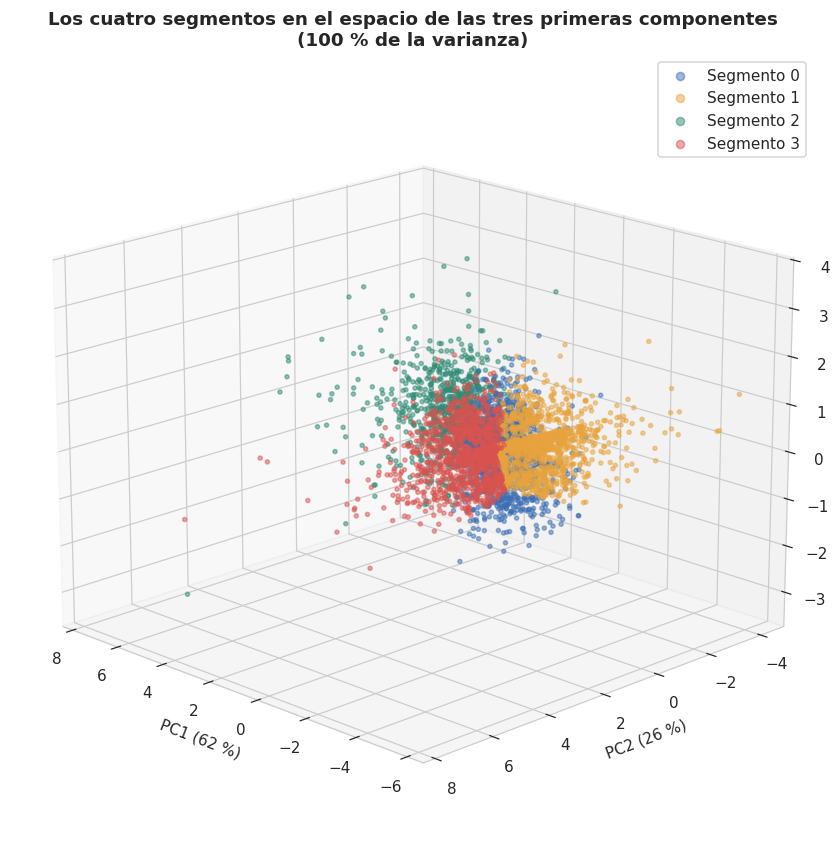

In [55]:
# Vista tridimensional de los segmentos, como en el Caso 9 pero en versión estática
coords3 = PCA(n_components=3).fit_transform(X)

fig = plt.figure(figsize=(11, 8))
eje = fig.add_subplot(111, projection='3d')
for s in sorted(clientes['segmento'].unique()):
    m = clientes['segmento'].values == s
    eje.scatter(coords3[m, 0], coords3[m, 1], coords3[m, 2],
                s=7, alpha=0.5, color=colores_seg[s], label=f'Segmento {s}')
eje.set_xlabel(f'PC1 ({var[0]:.0f} %)')
eje.set_ylabel(f'PC2 ({var[1]:.0f} %)')
eje.set_zlabel(f'PC3 ({var[2]:.0f} %)')
eje.set_title(f'Los cuatro segmentos en el espacio de las tres primeras componentes\n'
              f'({acum[2]:.0f} % de la varianza)', fontweight='bold')
eje.view_init(elev=18, azim=135)
eje.legend(markerscale=2)
plt.tight_layout()
plt.savefig('fig/f20_pca3d.png', bbox_inches='tight')
plt.show()

In [56]:
# Resumen comparativo de los tres algoritmos
resumen_alg = pd.DataFrame([
    {'Algoritmo': 'K-means (k=4)', 'Grupos': K,
     'Silueta': round(silhouette_score(X, clientes['segmento']), 4),
     'Ruido': 0, 'Acuerdo con K-means': '100,0 %'},
    {'Algoritmo': 'Jerárquico Ward (k=4)', 'Grupos': K,
     'Silueta': round(silhouette_score(X, clientes['segmento_jerarquico']), 4),
     'Ruido': 0, 'Acuerdo con K-means': f"{RES['coincidencia_jerarquico']} %".replace('.', ',')},
    {'Algoritmo': f'K-means sobre {n_comp} componentes', 'Grupos': K,
     'Silueta': RES['silueta_pca'], 'Ruido': 0,
     'Acuerdo con K-means': f"{RES['coincidencia_pca']} %".replace('.', ',')},
    {'Algoritmo': f'DBSCAN (eps={eps_elegido})', 'Grupos': n_grupos,
     'Silueta': round(silhouette_score(X[db.labels_ != -1], db.labels_[db.labels_ != -1]), 4)
     if n_grupos > 1 else float('nan'),
     'Ruido': n_ruido, 'Acuerdo con K-means': '—'},
])
print(resumen_alg.to_string(index=False))
RES['resumen_algoritmos'] = resumen_alg.to_dict('records')

                  Algoritmo  Grupos  Silueta  Ruido Acuerdo con K-means
              K-means (k=4)       4   0.2760      0             100,0 %
      Jerárquico Ward (k=4)       4   0.2020      0              73,4 %
K-means sobre 3 componentes       4   0.2754      0              98,6 %
           DBSCAN (eps=0.6)       2   0.2528    134                   —


---
# PARTE 10 — Perfiles de comportamiento en el tiempo

Las partes anteriores describen a cada cliente con **cuánto** y **cada cuánto** compra. Falta una
dimensión que el Caso 10 pone en el centro de todo su análisis: **la forma temporal del
comportamiento**.

El Caso 10 hace exactamente esto con el consumo eléctrico de un hogar: toma una serie continua, la
agrupa con `resample`, y con `pivot` la convierte en una matriz donde **cada fila es un día y cada
columna una hora**. Así cada día se vuelve un punto de 24 dimensiones y agrupar días parecidos es
agrupar perfiles de consumo. Esa misma idea se traslada acá: cada **cliente** se convierte en un
vector de 24 horas, o de 6 días de la semana, y se puede mirar si los segmentos que encontramos
tienen además hábitos horarios distintos.

In [57]:
# Matriz cliente x hora, igual que el pivot del Caso 10 pero con clientes en lugar de días
horas_cli = ventas_cli.pivot_table(index='CustomerID', columns='hora',
                                   values='InvoiceNo', aggfunc='nunique', fill_value=0)
horas_cli = horas_cli.reindex(columns=range(6, 21), fill_value=0)

# Se normaliza por fila: cada cliente suma 1, así se compara la forma y no el volumen
perfil_hora = horas_cli.div(horas_cli.sum(axis=1), axis=0).fillna(0)

# Matriz cliente x día de la semana
dias_cli = ventas_cli.pivot_table(index='CustomerID', columns='dia_semana',
                                  values='InvoiceNo', aggfunc='nunique', fill_value=0)
perfil_dia = dias_cli.div(dias_cli.sum(axis=1), axis=0).fillna(0)

print('Matriz cliente x hora :', perfil_hora.shape)
print('Matriz cliente x día  :', perfil_dia.shape)
perfil_hora.head()

Matriz cliente x hora : (4334, 15)
Matriz cliente x día  : (4334, 6)


hora,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20
CustomerID,,,,,,,,,,,,,,,
12346,0.0,0.0,0.000000,0.0,1.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.00,0.0
12347,0.0,0.0,0.142857,0.0,0.142857,0.0,0.142857,0.142857,0.285714,0.142857,0.0,0.0,0.0,0.00,0.0
12348,0.0,0.0,0.000000,0.0,0.500000,0.0,0.000000,0.250000,0.000000,0.000000,0.0,0.0,0.0,0.25,0.0
12349,0.0,0.0,0.000000,1.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.00,0.0
12350,0.0,0.0,0.000000,0.0,0.000000,0.0,0.000000,0.000000,0.000000,0.000000,1.0,0.0,0.0,0.00,0.0


Antes de graficar hay que reconocer una limitación de esta idea en nuestro contexto. En el Caso 10
cada fila era **un día completo con 24 mediciones reales**, así que el perfil siempre tenía forma.
Acá, en cambio, **la mitad de los clientes tiene una o dos facturas**: su perfil individual es un
pico del 100 % en una sola hora y cero en las demás, lo que no describe un hábito sino un único
evento. Por eso las curvas individuales se dibujan solo para los clientes con **cinco facturas o
más** —los únicos donde la palabra *hábito* significa algo— y la curva gruesa de cada segmento se
calcula agregando **todas** las facturas del segmento, que es una medida estable.

In [58]:
# Se agrega el segmento al índice, como hace el Caso 10 con set_index(..., append=True)
perfil_hora_seg = perfil_hora.set_index(clientes['segmento'].reindex(perfil_hora.index),
                                        append=True)
perfil_dia_seg = perfil_dia.set_index(clientes['segmento'].reindex(perfil_dia.index),
                                      append=True)

# Clientes con hábito observable: cinco facturas o más
recurrentes = clientes.index[clientes['frecuencia'] >= 5]
print(f'Clientes con 5 o más facturas: {len(recurrentes):,} '
      f'({len(recurrentes)/len(clientes)*100:.1f}% de la base)')

# Perfil agregado del segmento: todas sus facturas juntas, no el promedio de perfiles
agg_hora = (ventas_cli.merge(clientes[['segmento']], left_on='CustomerID', right_index=True)
            .pivot_table(index='segmento', columns='hora', values='InvoiceNo', aggfunc='nunique',
                         fill_value=0))
agg_hora = agg_hora.div(agg_hora.sum(axis=1), axis=0) * 100

agg_dia = (ventas_cli.merge(clientes[['segmento']], left_on='CustomerID', right_index=True)
           .pivot_table(index='segmento', columns='dia_semana', values='InvoiceNo',
                        aggfunc='nunique', fill_value=0))
agg_dia = agg_dia.div(agg_dia.sum(axis=1), axis=0) * 100

RES['agg_hora'] = agg_hora.round(1).to_dict()
RES['agg_dia'] = agg_dia.round(1).to_dict()
RES['n_recurrentes'] = int(len(recurrentes))
print()
print('Perfil semanal agregado por segmento (% de las facturas del segmento):')
print(agg_dia.round(1).to_string())

Clientes con 5 o más facturas: 1,101 (25.4% de la base)

Perfil semanal agregado por segmento (% de las facturas del segmento):
dia_semana     0     1     2     3     4     6
segmento                                      
0           15.4  16.5  17.7  21.3  13.7  15.5
1           14.7  15.6  18.1  22.5  15.3  13.8
2           15.2  17.8  19.1  21.8  15.7  10.4
3           16.7  16.6  18.6  21.5  15.7  10.8


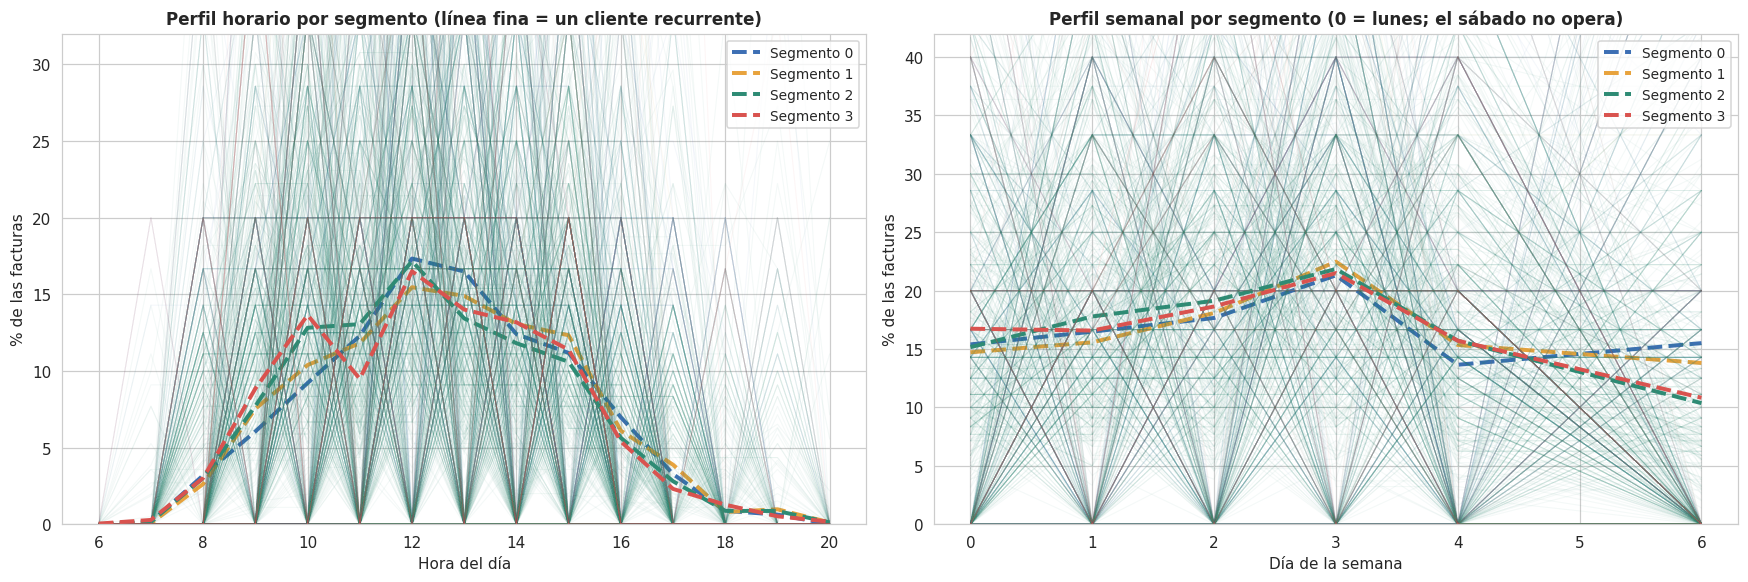

In [59]:
# Gráfica firma del Caso 10: curvas tenues de cada cliente y la del grupo en línea gruesa
fig, ax = plt.subplots(1, 2, figsize=(16, 5.4))
handles = []

for s in sorted(clientes['segmento'].unique()):
    idx = [i for i in perfil_hora_seg.xs(s, level='segmento').index if i in set(recurrentes)]
    sub = perfil_hora.loc[idx]
    if len(sub):
        ax[0].plot(sub.columns.values, sub.values.T * 100,
                   color=colores_seg[s], alpha=0.05, linewidth=0.7)
    ax[0].plot(agg_hora.columns.values, agg_hora.loc[s].values,
               color=colores_seg[s], linewidth=2.6, ls='--')

    subd = perfil_dia.loc[idx]
    if len(subd):
        ax[1].plot(subd.columns.values, subd.values.T * 100,
                   color=colores_seg[s], alpha=0.05, linewidth=0.7)
    ax[1].plot(agg_dia.columns.values, agg_dia.loc[s].values,
               color=colores_seg[s], linewidth=2.6, ls='--')

    handles.append(Line2D([0], [0], color=colores_seg[s], ls='--', linewidth=2.6,
                          label=f'Segmento {s}'))

ax[0].set_title('Perfil horario por segmento (línea fina = un cliente recurrente)',
                fontweight='bold', fontsize=11)
ax[0].set_xlabel('Hora del día'); ax[0].set_ylabel('% de las facturas')
ax[0].set_ylim(0, 32); ax[0].legend(handles=handles, fontsize=9)

ax[1].set_title('Perfil semanal por segmento (0 = lunes; el sábado no opera)',
                fontweight='bold', fontsize=11)
ax[1].set_xlabel('Día de la semana'); ax[1].set_ylabel('% de las facturas')
ax[1].set_ylim(0, 42); ax[1].legend(handles=handles, fontsize=9)

plt.tight_layout()
plt.savefig('fig/f21_perfiles_temporales.png', bbox_inches='tight', dpi=110)
plt.show()

In [60]:
# ¿El hábito temporal separa a los segmentos, o las cuatro curvas se superponen?
dif_hora = (agg_hora.max(axis=0) - agg_hora.min(axis=0)).max()
dif_dia = (agg_dia.max(axis=0) - agg_dia.min(axis=0)).max()

print('Perfil horario agregado por segmento (%):')
print(agg_hora.round(1).to_string())
print()
print(f'Separación máxima entre segmentos en cualquier hora: {dif_hora:.1f} puntos porcentuales')
print(f'Separación máxima entre segmentos en cualquier día  : {dif_dia:.1f} puntos porcentuales')

RES['dif_max_hora'] = round(float(dif_hora), 1)
RES['dif_max_dia'] = round(float(dif_dia), 1)

Perfil horario agregado por segmento (%):
hora       6    7    8    9     10    11    12    13    14    15   16   17   18   19   20
segmento                                                                                 
0         0.0  0.1  3.2  6.0   9.2  12.3  17.3  16.5  12.4  11.2  7.0  3.3  0.9  0.6  0.0
1         0.0  0.1  2.6  7.5  10.4  11.8  15.5  14.9  13.1  12.3  6.1  3.9  0.8  1.0  0.1
2         0.0  0.2  3.0  7.7  12.8  13.1  17.2  13.4  11.8  10.6  5.6  2.8  0.9  0.9  0.1
3         0.0  0.3  3.0  8.8  13.6   9.5  16.5  14.0  13.2  11.4  5.4  2.3  1.3  0.5  0.2

Separación máxima entre segmentos en cualquier hora: 4.4 puntos porcentuales
Separación máxima entre segmentos en cualquier día  : 5.1 puntos porcentuales


---
# PARTE 11 — Verificaciones adicionales

Tres comprobaciones que cierran el trabajo: si el escalador elegido cambia el resultado, cómo se
distribuyen los clientes por bandas de gasto, y cómo se ve la serie diaria con una media móvil.

In [61]:
# El Caso 9 escala con StandardScaler y el Caso 10 con MinMaxScaler. ¿Cambia algo?
X_minmax = MinMaxScaler().fit_transform(X_log)

km_mm = KMeans(n_clusters=K, n_init='auto', random_state=42)
seg_mm = km_mm.fit_predict(X_minmax)

sil_mm = silhouette_score(X_minmax, seg_mm)
cruce_mm = pd.crosstab(clientes['segmento'], seg_mm,
                       rownames=['StandardScaler'], colnames=['MinMaxScaler'])
coinc_mm = cruce_mm.max(axis=1).sum() / len(clientes) * 100

print(f'Silueta con StandardScaler (Caso 9) : {sil_final:.4f}')
print(f'Silueta con MinMaxScaler   (Caso 10): {sil_mm:.4f}')
print(f'Clientes que caen en el mismo grupo : {coinc_mm:.1f}%')
print()
print(cruce_mm.to_string())

RES['silueta_minmax'] = round(float(sil_mm), 4)
RES['coincidencia_minmax'] = round(float(coinc_mm), 1)

Silueta con StandardScaler (Caso 9) : 0.2760
Silueta con MinMaxScaler   (Caso 10): 0.3347
Clientes que caen en el mismo grupo : 55.3%

MinMaxScaler      0    1    2    3
StandardScaler                    
0               261   12  483  326
1                 0  878  366    1
2               484    0    0  346
3                 8  550  322  297


In [62]:
# Bandas de gasto con pd.cut, como el Caso 9 agrupa en rangos
bandas = pd.cut(clientes['monetario'],
                bins=[0, 250, 1000, 5000, 20000, np.inf],
                labels=['< 250', '250 – 1.000', '1.000 – 5.000',
                        '5.000 – 20.000', '> 20.000'])
clientes['banda_gasto'] = bandas

tabla_bandas = pd.crosstab(bandas, clientes['segmento'], margins=True, margins_name='Total')
print('Clientes por banda de gasto y segmento:')
print(tabla_bandas.to_string())

aporte = clientes.groupby('banda_gasto', observed=True)['monetario'].agg(
    clientes='size', gasto_total='sum')
aporte['% clientes'] = (aporte['clientes'] / aporte['clientes'].sum() * 100).round(1)
aporte['% de la venta'] = (aporte['gasto_total'] / aporte['gasto_total'].sum() * 100).round(1)
print()
print(aporte.round(0).to_string())

RES['bandas_gasto'] = {str(i): {'clientes': int(r['clientes']),
                                'pct_clientes': float(r['% clientes']),
                                'pct_venta': float(r['% de la venta'])}
                       for i, r in aporte.iterrows()}

Clientes por banda de gasto y segmento:
segmento           0     1    2     3  Total
monetario                                   
< 250             78   799    0     0    877
250 – 1.000      710   446    0   661   1817
1.000 – 5.000    294     0  575   503   1372
5.000 – 20.000     0     0  216    10    226
> 20.000           0     0   39     3     42
Total           1082  1245  830  1177   4334

                clientes  gasto_total  % clientes  % de la venta
banda_gasto                                                     
< 250                877     133536.0        20.0            2.0
250 – 1.000         1817     979509.0        42.0           11.0
1.000 – 5.000       1372    2944905.0        32.0           34.0
5.000 – 20.000       226    1904162.0         5.0           22.0
> 20.000              42    2775115.0         1.0           32.0


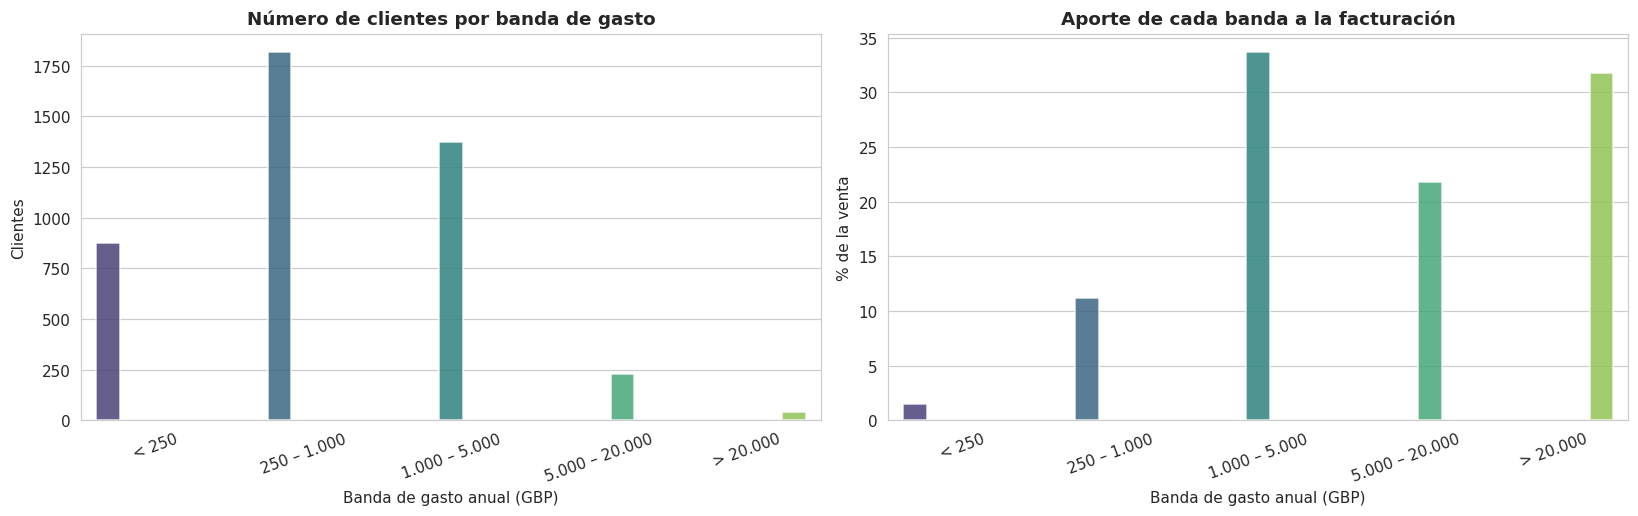

In [63]:
# Un countplot y un barplot, los dos gráficos de conteo que usa el Caso 9
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))

sns.countplot(data=clientes, x='banda_gasto', hue='banda_gasto', legend=False,
              palette='viridis', alpha=0.85, ax=ax[0])
ax[0].set_title('Número de clientes por banda de gasto', fontweight='bold')
ax[0].set_xlabel('Banda de gasto anual (GBP)'); ax[0].set_ylabel('Clientes')
ax[0].tick_params(axis='x', rotation=20)

resumen_banda = aporte.reset_index()
sns.barplot(data=resumen_banda, x='banda_gasto', y='% de la venta',
            hue='banda_gasto', legend=False, palette='viridis', alpha=0.85, ax=ax[1])
ax[1].set_title('Aporte de cada banda a la facturación', fontweight='bold')
ax[1].set_xlabel('Banda de gasto anual (GBP)'); ax[1].set_ylabel('% de la venta')
ax[1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.savefig('fig/f22_bandas_gasto.png', bbox_inches='tight')
plt.show()

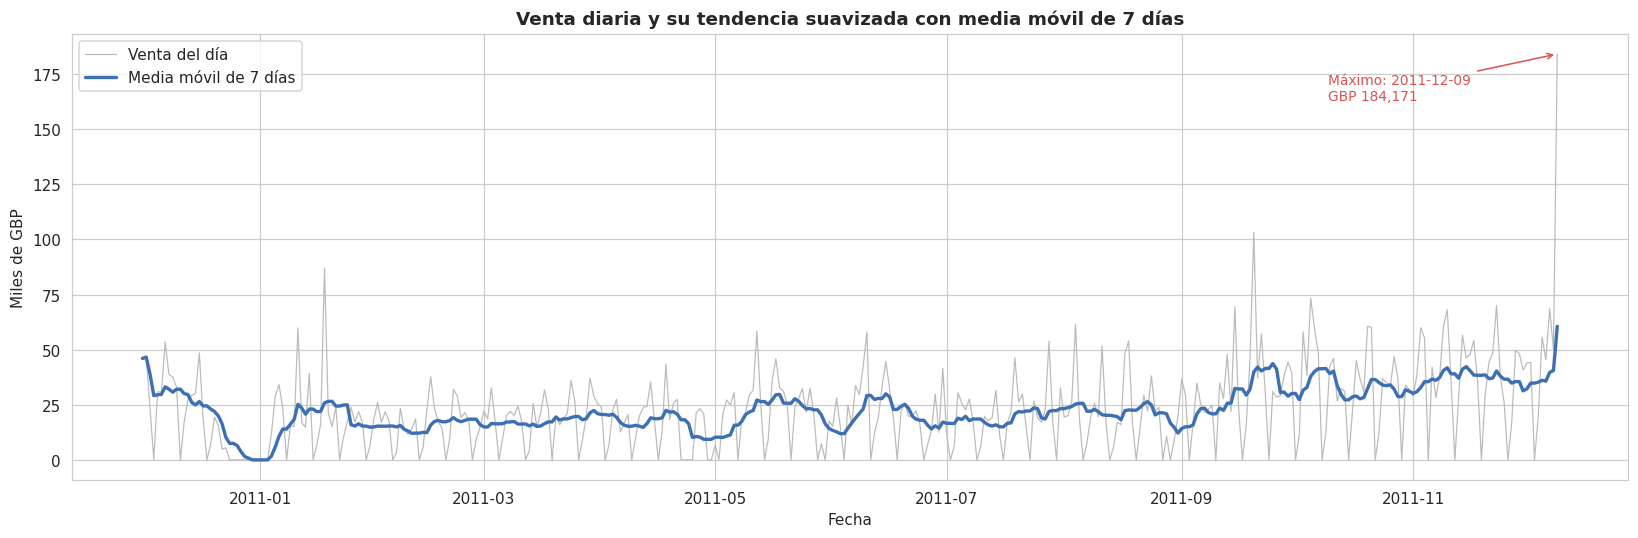

Días con venta cero: 69
De ellos, sábados  : 53 de 53
Día de mayor venta : 2011-12-09 con GBP 184,171


In [64]:
# Serie diaria con media móvil de 7 días (referente del Caso 3 y el Caso 4)
serie_dia_val = ventas_cli.set_index('InvoiceDate')['valor'].resample('D').sum() / 1000
movil = serie_dia_val.rolling(7, min_periods=1).mean()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(serie_dia_val.index, serie_dia_val.values, color='#BBBBBB', linewidth=0.8,
        label='Venta del día')
ax.plot(movil.index, movil.values, color='#3D6FB4', linewidth=2.2,
        label='Media móvil de 7 días')

pico = serie_dia_val.idxmax()
ax.annotate(f'Máximo: {pico.date()}\nGBP {serie_dia_val.max()*1000:,.0f}',
            xy=(pico, serie_dia_val.max()),
            xytext=(-150, -30), textcoords='offset points', fontsize=9, color='#D9534F',
            arrowprops=dict(arrowstyle='->', color='#D9534F'))

ax.set_title('Venta diaria y su tendencia suavizada con media móvil de 7 días',
             fontweight='bold')
ax.set_xlabel('Fecha'); ax.set_ylabel('Miles de GBP')
ax.legend()
plt.tight_layout()
plt.savefig('fig/f23_serie_diaria.png', bbox_inches='tight')
plt.show()

sabados = serie_dia_val[serie_dia_val.index.dayofweek == 5]
print(f'Días con venta cero: {int((serie_dia_val == 0).sum())}')
print(f'De ellos, sábados  : {int((sabados == 0).sum())} de {len(sabados)}')
print(f'Día de mayor venta : {pico.date()} con GBP {serie_dia_val.max()*1000:,.0f}')

RES['dias_cero'] = int((serie_dia_val == 0).sum())
RES['sabados_cero'] = int((sabados == 0).sum())
RES['sabados_total'] = int(len(sabados))
RES['dia_pico'] = str(pico.date())
RES['dia_pico_valor'] = round(float(serie_dia_val.max() * 1000), 0)

---
# PARTE 12 — Análisis por país

Todo el análisis anterior por cliente se construyó sobre las **391.150 líneas con `CustomerID`**,
porque sin identificar al comprador no se puede calcular su recencia ni su frecuencia. Pero conviene
señalar algo que esa restricción **no** implica: la columna `Country` **no tiene un solo valor
faltante** en las 541.909 filas del archivo. Es decir, las 135.080 líneas anónimas sí tienen país.

Por eso esta parte hace una **excepción deliberada al criterio del resto del trabajo**: los totales
por país —venta, facturas, ticket medio— se calculan sobre **todas** las líneas de venta limpias,
incluyendo las anónimas, porque para atribuir una venta a un país no hace falta saber quién la hizo.
Solo el **conteo de clientes** se restringe al bloque identificado, y así queda rotulado en la tabla
para que las dos columnas no se lean como si midieran lo mismo.

In [65]:
# Verificación previa: ¿el bloque sin cliente tiene país?
sin_cliente_mask = retail['CustomerID'].isna()
print('Filas sin CustomerID          :', f'{int(sin_cliente_mask.sum()):,}')
print('De ellas, con país registrado :', f"{int((sin_cliente_mask & retail['Country'].notna()).sum()):,}")
print('Nulos en la columna Country   :', int(retail['Country'].isna().sum()))
print()
print('Cómo se reparte por país el bloque anónimo:')
print(retail.loc[sin_cliente_mask, 'Country'].value_counts().head(6).to_string())

RES['anon_por_pais'] = {str(k): int(v) for k, v in
                        retail.loc[sin_cliente_mask, 'Country'].value_counts().head(6).items()}

Filas sin CustomerID          : 135,080
De ellas, con país registrado : 135,080
Nulos en la columna Country   : 0

Cómo se reparte por país el bloque anónimo:
Country
United Kingdom    133600
EIRE                 711
Hong Kong            288
Unspecified          202
Switzerland          125
France                66


El reparto es contundente y tiene una consecuencia metodológica: **el problema del `CustomerID`
faltante es prácticamente un problema británico**. De las 135.080 líneas anónimas, 133.600 —el
98,9 %— corresponden al Reino Unido. Fuera de allí el registro está casi completo, de modo que para
los mercados extranjeros el análisis por cliente de las partes anteriores no sufre ningún sesgo por
esta causa.

In [66]:
# Tabla por país. Ojo: 'venta' y 'facturas' usan TODAS las líneas limpias (incluidas las
# anónimas); 'clientes' solo puede contar las identificadas.
paises = ventas.groupby('Country').agg(
    lineas=('valor', 'size'),
    facturas=('InvoiceNo', 'nunique'),
    clientes_identificados=('CustomerID', 'nunique'),
    venta=('valor', 'sum'),
)
paises['ticket_medio'] = paises['venta'] / paises['facturas']
paises['% de la venta'] = paises['venta'] / paises['venta'].sum() * 100
paises = paises.sort_values('venta', ascending=False)

print('Países en la base limpia:', len(paises))
print(f"Venta total considerada : GBP {paises['venta'].sum():,.0f}")
print()
print(paises.head(14).round(1).to_string())

RES['n_paises_limpios'] = int(len(paises))
RES['venta_total_paises'] = round(float(paises['venta'].sum()), 0)
RES['tabla_paises'] = paises.head(10).round(1).reset_index().to_dict('records')
RES['uk_pct_venta'] = round(float(paises.loc['United Kingdom', '% de la venta']), 1)
RES['uk_ticket'] = round(float(paises.loc['United Kingdom', 'ticket_medio']), 1)

Países en la base limpia: 38
Venta total considerada : GBP 10,246,821

                 lineas  facturas  clientes_identificados      venta  ticket_medio  % de la venta
Country                                                                                          
United Kingdom   478838     17901                    3916  8724045.2         487.3           85.1
Netherlands        2322        93                       9   283889.3        3052.6            2.8
EIRE               7768       282                       3   270850.9         960.5            2.6
Germany            8643       443                      94   205381.2         463.6            2.0
France             8085       382                      87   184493.0         483.0            1.8
Australia          1180        56                       9   138103.8        2466.1            1.3
Spain              2417        88                      30    55706.6         633.0            0.5
Switzerland        1927        50              

In [67]:
# Cuánto de la venta de cada país proviene del bloque sin identificar
anon_pais = ventas[ventas['CustomerID'].isna()].groupby('Country')['valor'].sum()
pct_anon = (anon_pais / paises['venta'] * 100).fillna(0)

# Y qué tan concentrado está cada país en su mayor cliente identificado
conc = []
for pais in paises.head(12).index:
    sub = ventas[(ventas['Country'] == pais) & ventas['CustomerID'].notna()]
    if not len(sub):
        continue
    por_cli = sub.groupby('CustomerID')['valor'].sum().sort_values(ascending=False)
    conc.append({'País': pais,
                 'Clientes': len(por_cli),
                 '% del mayor cliente': round(por_cli.iloc[0] / por_cli.sum() * 100, 1),
                 'Mayor cliente': int(por_cli.index[0]),
                 '% venta sin identificar': round(float(pct_anon.get(pais, 0)), 1)})

concentracion = pd.DataFrame(conc)
print(concentracion.to_string(index=False))

RES['concentracion_pais'] = concentracion.to_dict('records')

          País  Clientes  % del mayor cliente  Mayor cliente  % venta sin identificar
United Kingdom      3916                  3.6          18102                     17.0
   Netherlands         9                 98.3          14646                      0.0
          EIRE         3                 53.0          14911                      5.1
       Germany        94                  8.5          12471                      0.0
        France        87                 10.2          12731                      0.4
     Australia         9                 90.2          12415                      0.0
         Spain        30                 21.5          12557                      0.0
   Switzerland        21                 21.1          12409                      1.2
         Japan         8                 57.3          12753                      0.0
       Belgium        25                 12.8          12362                      0.0
        Sweden         8                 86.3         

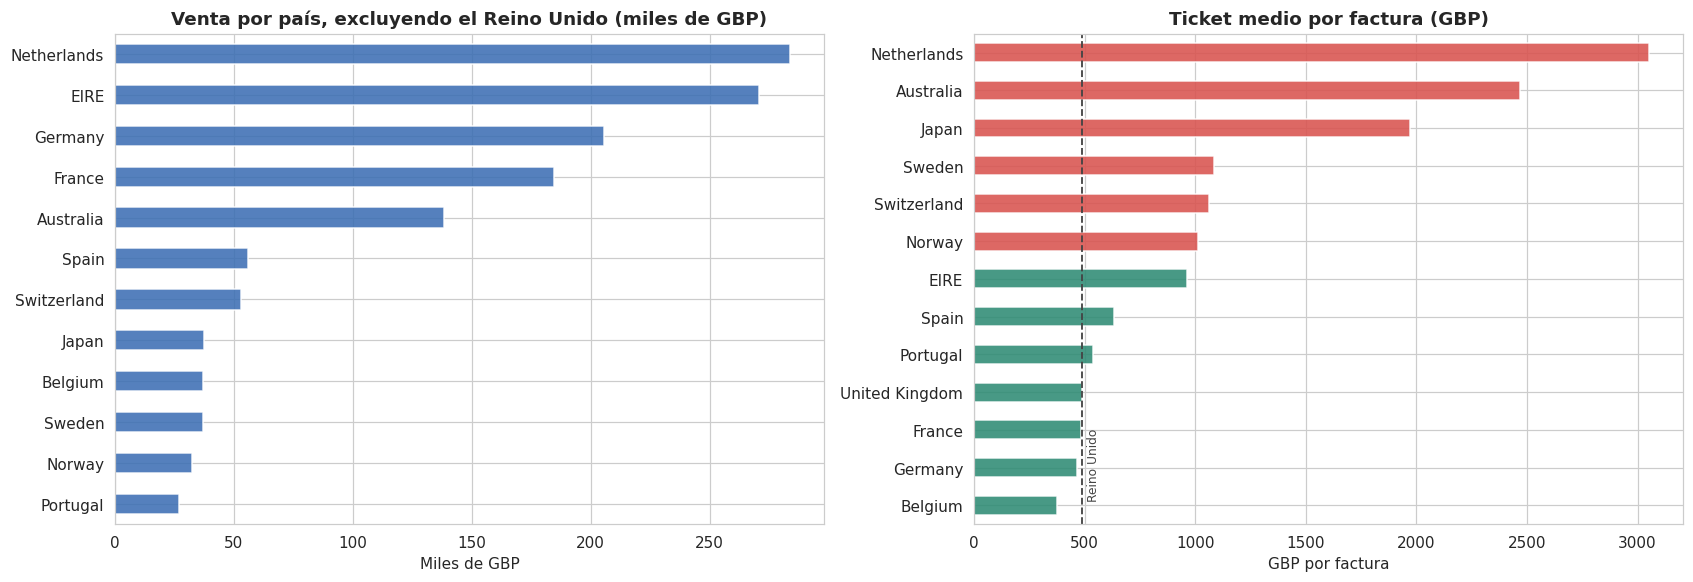

In [68]:
# Venta y ticket medio por país (sin el Reino Unido en el panel de venta, que aplasta la escala)
top = paises.head(13)
resto = top.drop('United Kingdom')

fig, ax = plt.subplots(1, 2, figsize=(15.5, 5.4))

(resto['venta'] / 1000).sort_values().plot(kind='barh', ax=ax[0], color='#3D6FB4', alpha=0.88)
ax[0].set_title('Venta por país, excluyendo el Reino Unido (miles de GBP)', fontweight='bold')
ax[0].set_xlabel('Miles de GBP'); ax[0].set_ylabel('')

colores_t = ['#D9534F' if v > paises.loc['United Kingdom', 'ticket_medio'] * 2 else '#2E8B74'
             for v in top['ticket_medio'].sort_values().values]
top['ticket_medio'].sort_values().plot(kind='barh', ax=ax[1], color=colores_t, alpha=0.88)
ax[1].axvline(paises.loc['United Kingdom', 'ticket_medio'], color='#444444', ls='--',
              linewidth=1.2)
ax[1].text(paises.loc['United Kingdom', 'ticket_medio'] * 1.05, 0.2,
           'Reino Unido', rotation=90, fontsize=8, color='#444444')
ax[1].set_title('Ticket medio por factura (GBP)', fontweight='bold')
ax[1].set_xlabel('GBP por factura'); ax[1].set_ylabel('')

plt.tight_layout()
plt.savefig('fig/f24_paises_venta.png', bbox_inches='tight')
plt.show()

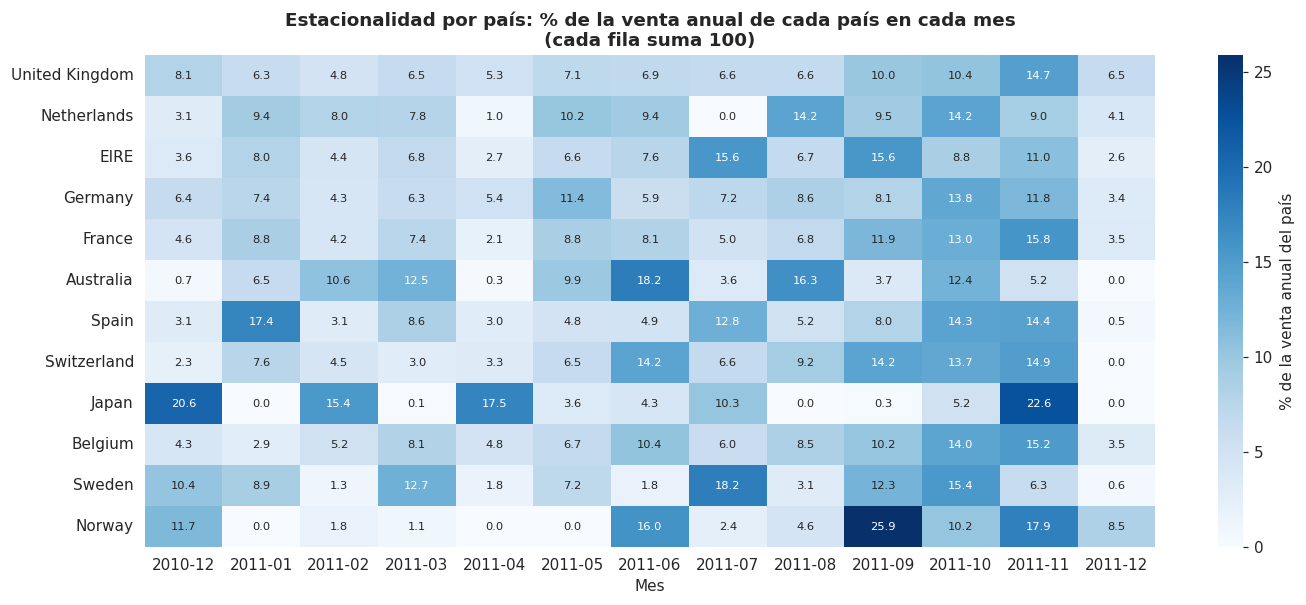

Mes más fuerte de cada país:
Country
United Kingdom    2011-11
Netherlands       2011-10
EIRE              2011-09
Germany           2011-10
France            2011-11
Australia         2011-06
Spain             2011-01
Switzerland       2011-11
Japan             2011-11
Belgium           2011-11
Sweden            2011-07
Norway            2011-09


In [69]:
# Mapa de calor país x mes, con la misma técnica de pivot_table del Caso 9
ventas_mes = ventas.copy()
ventas_mes['mes'] = ventas_mes['InvoiceDate'].dt.to_period('M').astype(str)

pais_mes = ventas_mes[ventas_mes['Country'].isin(paises.head(12).index)].pivot_table(
    index='Country', columns='mes', values='valor', aggfunc='sum', fill_value=0)
pais_mes = pais_mes.reindex(paises.head(12).index)

# Cada fila suma 100: así se compara el calendario de cada país, no su tamaño
pais_mes_n = pais_mes.div(pais_mes.sum(axis=1), axis=0) * 100

plt.figure(figsize=(13, 5.6))
sns.heatmap(pais_mes_n, cmap='Blues', annot=True, fmt='.1f', annot_kws={'size': 7.5},
            cbar_kws={'label': '% de la venta anual del país'})
plt.title('Estacionalidad por país: % de la venta anual de cada país en cada mes\n'
          '(cada fila suma 100)', fontweight='bold')
plt.xlabel('Mes'); plt.ylabel('')
plt.tight_layout()
plt.savefig('fig/f25_pais_mes.png', bbox_inches='tight')
plt.show()

print('Mes más fuerte de cada país:')
print(pais_mes_n.idxmax(axis=1).to_string())
RES['mes_top_pais'] = {str(k): str(v) for k, v in pais_mes_n.idxmax(axis=1).items()}

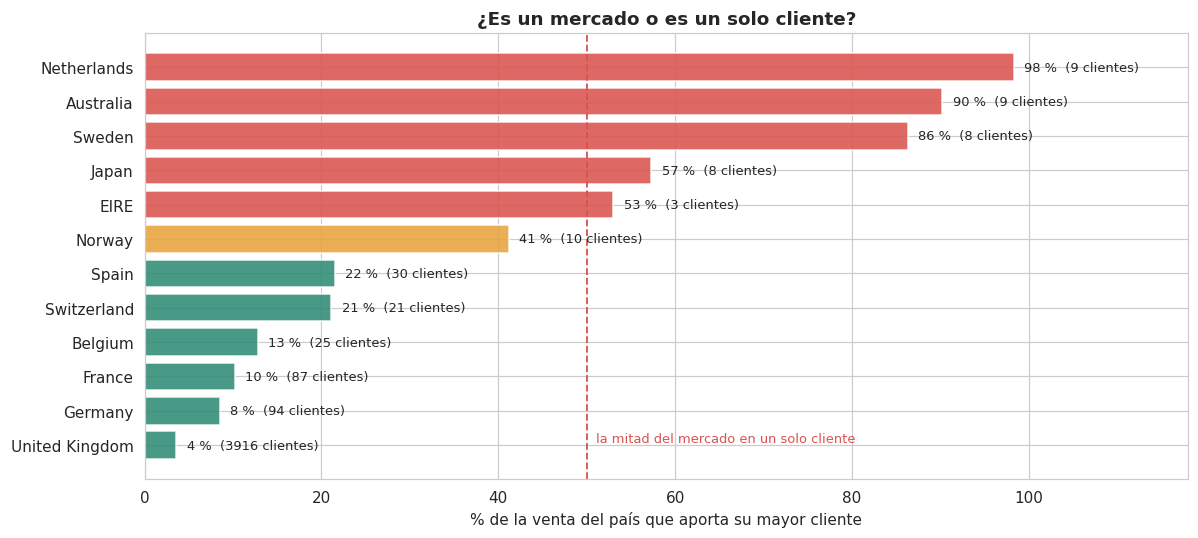

In [70]:
# Concentración: qué parte de cada mercado depende de un solo comprador
fig, ax = plt.subplots(figsize=(11, 5))
cc = concentracion.sort_values('% del mayor cliente')
colores_c = ['#D9534F' if v >= 50 else '#E8A33D' if v >= 25 else '#2E8B74'
             for v in cc['% del mayor cliente']]
ax.barh(cc['País'], cc['% del mayor cliente'], color=colores_c, alpha=0.88)
ax.axvline(50, color='#D9534F', ls='--', linewidth=1.2)
ax.text(51, 0.1, 'la mitad del mercado en un solo cliente', fontsize=8.5, color='#D9534F')
for y, (v, n) in enumerate(zip(cc['% del mayor cliente'], cc['Clientes'])):
    ax.text(v + 1.2, y, f'{v:.0f} %  ({n} clientes)', va='center', fontsize=8.5)
ax.set_xlim(0, 118)
ax.set_xlabel('% de la venta del país que aporta su mayor cliente')
ax.set_title('¿Es un mercado o es un solo cliente?', fontweight='bold')
plt.tight_layout()
plt.savefig('fig/f26_concentracion_pais.png', bbox_inches='tight')
plt.show()

**Qué muestra este corte.** Tres cosas que el análisis por cliente no podía ver.

La primera es que **el Reino Unido pesa menos en dinero que en volumen**: concentra el 91,4 % de las
líneas pero el 85,1 % de la venta. La diferencia la explican los tickets. Un pedido británico
promedia GBP 487, mientras que uno neerlandés promedia GBP 3.053, uno australiano GBP 2.466 y uno
japonés GBP 1.969. Fuera del Reino Unido la tienda no vende al detal: vende contenedores.

La segunda es que **varios "países" no son mercados sino clientes**. En los Países Bajos, el 98,3 %
de la venta identificada la hace un único comprador —el cliente 14646, que además es el número uno
global de toda la base—; en Australia el 90,2 % lo hace uno solo, en Suecia el 86,3 % y en Japón el
57,3 %. Tratar a esos países como segmentos geográficos sería un error de lectura: son cuentas
individuales. Los únicos mercados extranjeros con estructura real son **Alemania (94 clientes, su
mayor comprador aporta el 8,5 %)** y **Francia (87 clientes, el 10,2 %)**.

La tercera es la que valida haber hecho este corte: **el faltante de `CustomerID` no está repartido
al azar**. El 17,0 % de la venta británica proviene de líneas sin identificar, mientras que en los
Países Bajos, Alemania, Australia, España, Japón, Bélgica, Suecia y Noruega esa proporción es
**exactamente cero**. Dicho de otro modo, la parte del negocio que la segmentación no alcanza a
describir es casi enteramente doméstica, y los mercados de exportación quedan cubiertos por completo.

In [71]:
# Guardamos todo para poder construir el informe con números reales y no de memoria
with open('resultados.json', 'w', encoding='utf-8') as f:
    json.dump(RES, f, ensure_ascii=False, indent=1, default=str)

clientes.to_csv('clientes_segmentados.csv')
print('Guardados resultados.json y clientes_segmentados.csv')
print('Figuras en la carpeta fig:', sorted(os.listdir('fig')))

Guardados resultados.json y clientes_segmentados.csv
Figuras en la carpeta fig: ['f00_composicion.png', 'f01_temporal.png', 'f02_heatmap_hora_dia.png', 'f03_rfm_distribuciones.png', 'f04_correlacion.png', 'f05_metricas_k.png', 'f06_perfiles_segmento.png', 'f07_aporte_segmentos.png', 'f08_dendrograma.png', 'f09_transacciones_anomalas.png', 'f10_clientes_atipicos.png', 'f11_pca_tsne.png', 'f12_concentracion.png', 'f13_top_productos.png', 'f14_mapa_segmentos.png', 'f15_anomalias_mes.png', 'f16_varianza_pca.png', 'f17_cargas_pca.png', 'f18_dbscan_barrido.png', 'f19_comparacion_algoritmos.png', 'f20_pca3d.png', 'f21_perfiles_temporales.png', 'f22_bandas_gasto.png', 'f23_serie_diaria.png', 'f24_paises_venta.png', 'f25_pais_mes.png', 'f26_concentracion_pais.png']
